In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold
from lightgbm import LGBMRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

In [2]:
DATA_PATH = Path("train.csv")
sales_record = pd.read_csv(DATA_PATH)

In [3]:
#understanding the training data

In [4]:
sales_record.head()

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36


In [5]:
sales_record.info()

<class 'pandas.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   6818 non-null   str    
 1   product_code         6818 non-null   str    
 2   product_weight_kg    5593 non-null   float64
 3   fat_content          6818 non-null   str    
 4   shelf_visibility     6818 non-null   float64
 5   product_category     6818 non-null   str    
 6   product_price        6818 non-null   float64
 7   store_code           6818 non-null   str    
 8   store_age_years      6818 non-null   int64  
 9   store_size           4899 non-null   str    
 10  store_location_tier  6818 non-null   str    
 11  store_format         6818 non-null   str    
 12  total_sales          6818 non-null   float64
dtypes: float64(4), int64(1), str(8)
memory usage: 692.6 KB


In [6]:
sales_record.describe()

,product_weight_kg,shelf_visibility,product_price,store_age_years,total_sales
count,5593.000000,6818.000000,6818.000000,6818.000000,6818.000000
mean,12.850876,0.065527,140.473623,34.178205,2174.756574
std,4.646542,0.051566,62.413513,8.384574,1697.894956
min,4.482000,0.000000,31.110000,23.000000,32.700000
25%,8.750000,0.026600,93.280000,28.000000,834.792500
50%,12.647000,0.053200,142.065000,33.000000,1790.890000
75%,16.894000,0.093400,185.987500,45.000000,3092.587500
max,21.883000,0.320100,273.040000,47.000000,12996.820000


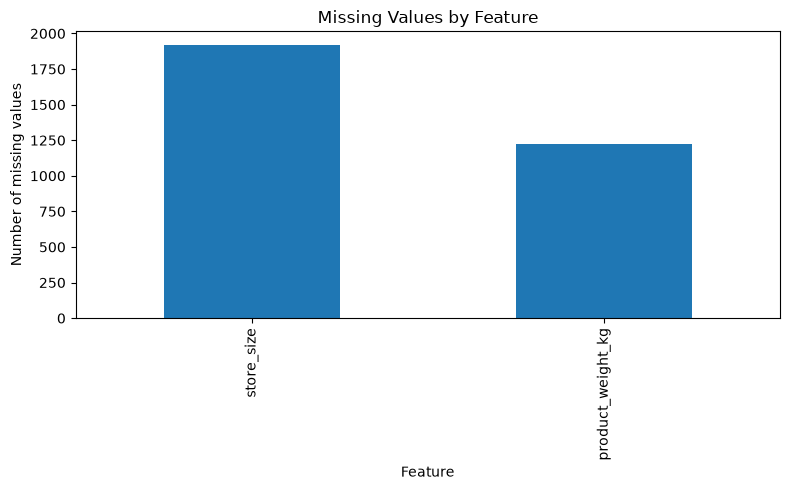

In [7]:
#checking for features with missing values

missing = sales_record.isna().sum()

missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(8, 5))

missing.plot(kind="bar")

plt.title("Missing Values by Feature")
plt.xlabel("Feature")
plt.ylabel("Number of missing values")

plt.tight_layout()
plt.show()

In [8]:
#Exploratory Data Analysis

In [9]:
#exploring target variable(total_sales)

print(sales_record["total_sales"].describe())

print("\nMissing values:")
print(sales_record["total_sales"].isna().sum())

print("\nNumber of unique values:")
print(sales_record["total_sales"].nunique())

count     6818.000000
mean      2174.756574
std       1697.894956
min         32.700000
25%        834.792500
50%       1790.890000
75%       3092.587500
max      12996.820000
Name: total_sales, dtype: float64

Missing values:
0

Number of unique values:
6776


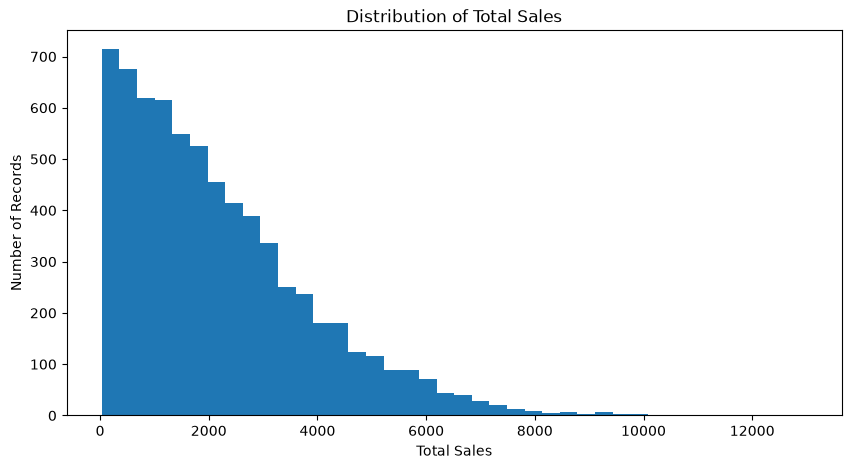

In [17]:
#total_sales distribution

plt.figure(figsize=(10, 5))

plt.hist(sales_record["total_sales"], bins=40)

plt.xlabel("Total Sales")
plt.ylabel("Number of Records")
plt.title("Distribution of Total Sales")

plt.show()

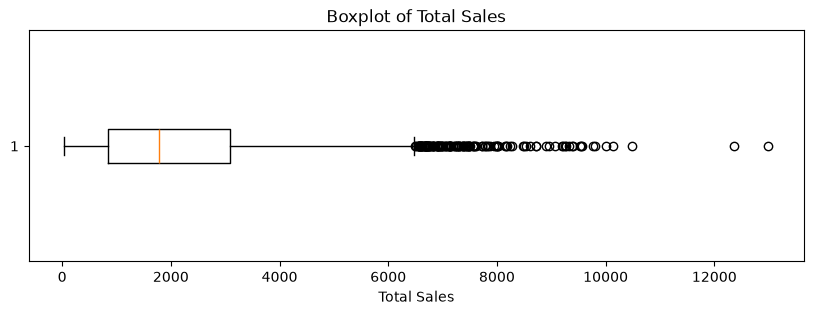

In [16]:
#total_sales extreme values

plt.figure(figsize=(10, 3))

plt.boxplot(sales_record["total_sales"], orientation="horizontal")

plt.xlabel("Total Sales")
plt.title("Boxplot of Total Sales")

plt.show()

In [15]:
#total_sales outliers using IQR method

Q1 = sales_record["total_sales"].quantile(0.25)
Q3 = sales_record["total_sales"].quantile(0.75)

IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)

outliers = sales_record[
    (sales_record["total_sales"] < lower_fence) |
    (sales_record["total_sales"] > upper_fence)
]

print("\nNumber of IQR outliers:", len(outliers))
print("Percentage of observations:", len(outliers) / len(sales_record) * 100)

Q1: 834.7925
Q3: 3092.5874999999996
IQR: 2257.7949999999996
Lower fence: -2551.899999999999
Upper fence: 6479.279999999999

Number of IQR outliers: 144
Percentage of observations: 2.112056321501907


In [13]:
#total_sales distribution in percentile

print(
    sales_record["total_sales"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00]
    )
)

0.00       32.7000
0.01       81.2017
0.05      188.1190
0.25      834.7925
0.50     1790.8900
0.75     3092.5875
0.95     5557.1910
0.99     7261.3893
1.00    12996.8200
Name: total_sales, dtype: float64


In [14]:
#total_sales skewness 
print("Skewness:", sales_record["total_sales"].skew())

Skewness: 1.1539947519138116


In [18]:
#numerical features EDA

In [30]:
#shelf_visibility
sales_record["shelf_visibility"].describe()

count    6818.000000
mean        0.065527
std         0.051566
min         0.000000
25%         0.026600
50%         0.053200
75%         0.093400
max         0.320100
Name: shelf_visibility, dtype: float64

In [20]:
print("\nNumber of unique values:")
print(sales_record["shelf_visibility"].nunique())

print("\nMissing values:")
print(sales_record["shelf_visibility"].isna().sum())

print("\nNumber of zero values:")
print((sales_record["shelf_visibility"] == 0).sum())



Number of unique values:
1732

Missing values:
0

Number of zero values:
422


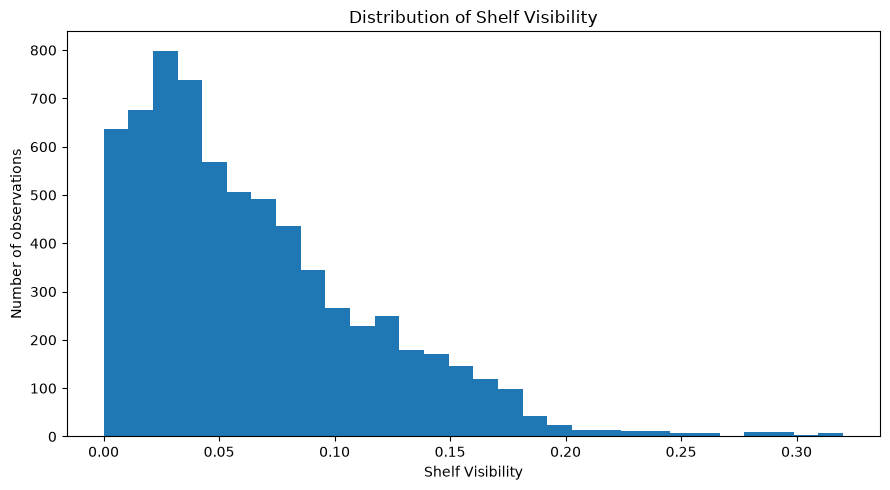

In [21]:
#shelf_visibility distribution

plt.figure(figsize=(9, 5))

plt.hist(sales_record["shelf_visibility"], bins=30)

plt.title("Distribution of Shelf Visibility")
plt.xlabel("Shelf Visibility")
plt.ylabel("Number of observations")

plt.tight_layout()
plt.show()

In [22]:
print(
    sales_record["shelf_visibility"]
      .value_counts(dropna=False)
      .sort_index()
)

shelf_visibility
0.0000    422
0.0035      1
0.0036      3
0.0037      1
0.0052      2
         ... 
0.3161      1
0.3170      1
0.3177      1
0.3183      1
0.3201      1
Name: count, Length: 1732, dtype: int64


In [23]:
#number of instances in different visibility ranges.

visibility_bins = pd.cut(
    sales_record["shelf_visibility"],
    bins=[-0.0001, 0, 0.01, 0.05, 0.10, 0.20, 0.40],
    include_lowest=True
)

print(
    visibility_bins.value_counts()
                  .sort_index()
)

shelf_visibility
(-0.0011, 0.0]     422
(0.0, 0.01]        176
(0.01, 0.05]      2671
(0.05, 0.1]       2030
(0.1, 0.2]        1415
(0.2, 0.4]         104
Name: count, dtype: int64


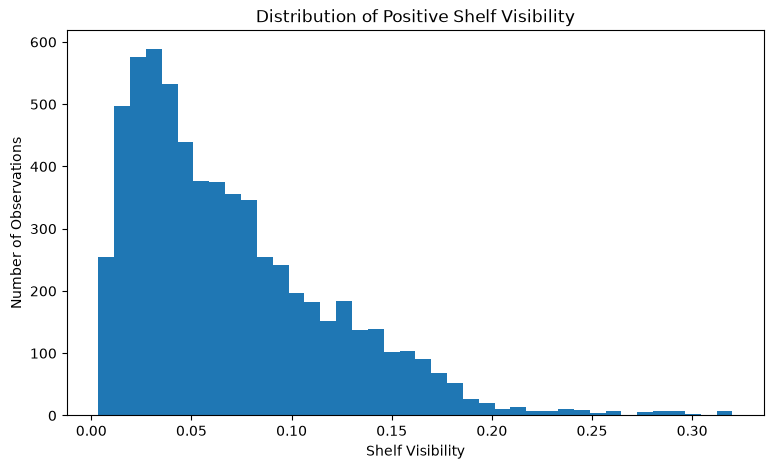

In [24]:
#positive shelf_visibility distribution

positive_visibility = sales_record.loc[
    sales_record["shelf_visibility"] > 0,
    "shelf_visibility"
]

plt.figure(figsize=(9, 5))

plt.hist(positive_visibility, bins=40)

plt.title("Distribution of Positive Shelf Visibility")
plt.xlabel("Shelf Visibility")
plt.ylabel("Number of Observations")

plt.show()

In [25]:
zero_visibility = (sales_record["shelf_visibility"] == 0).sum()
positive_visibility = (sales_record["shelf_visibility"] > 0).sum()

print("Zero values:", zero_visibility)
print("Positive values:", positive_visibility)
print("Zero percentage:", zero_visibility / len(sales_record) * 100)
print("Positive percentage:", positive_visibility / len(sales_record) * 100)

Zero values: 422
Positive values: 6396
Zero percentage: 6.189498386623643
Positive percentage: 93.81050161337635


store_code
STORE-7WS    44
STORE-89Z    41
STORE-9RG    46
STORE-AGY    46
STORE-DKU    50
STORE-HL7    58
STORE-JOR    25
STORE-OYG    42
STORE-T5G    26
STORE-YLW    44
Name: count, dtype: int64


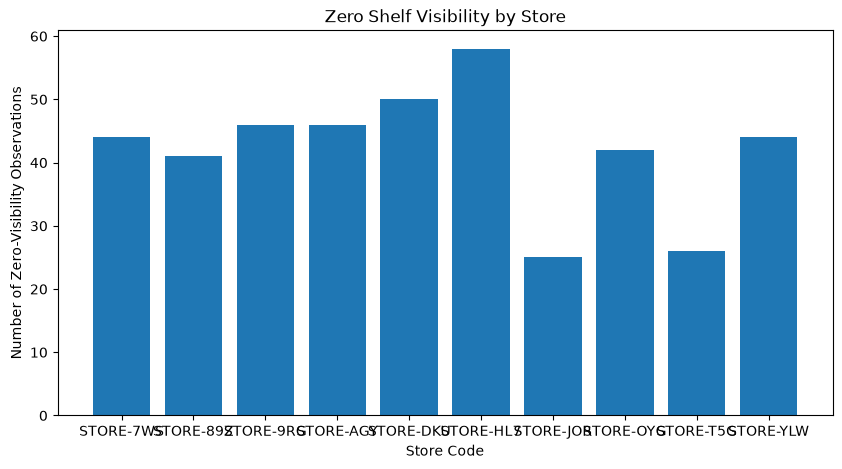

In [26]:
#Zero Visibility by store

zero_visibility_by_store = (
    sales_record.loc[sales_record["shelf_visibility"] == 0, "store_code"]
      .value_counts()
      .sort_index()
)

print(zero_visibility_by_store)

plt.figure(figsize=(10, 5))

plt.bar(
    zero_visibility_by_store.index,
    zero_visibility_by_store.values
)

plt.title("Zero Shelf Visibility by Store")
plt.xlabel("Store Code")
plt.ylabel("Number of Zero-Visibility Observations")

plt.show()

In [27]:
#percentage of each store's observations with zero shelf_visibility

zero_rate_by_store = (
    sales_record.groupby("store_code")["shelf_visibility"]
      .apply(lambda x: (x == 0).mean() * 100)
      .sort_values(ascending=False)
)

print(zero_rate_by_store)

store_code
STORE-HL7    7.816712
STORE-DKU    6.793478
STORE-AGY    6.149733
STORE-9RG    6.117021
STORE-T5G    6.088993
STORE-7WS    5.882353
STORE-YLW    5.835544
STORE-JOR    5.694761
STORE-OYG    5.645161
STORE-89Z    5.631868
Name: shelf_visibility, dtype: float64


product_category
fruits and vegetables    72
snack foods              57
household                43
frozen foods             35
baking goods             30
soft drinks              30
dairy                    29
canned                   29
health and hygiene       27
meat                     19
hard drinks              15
breads                   14
starchy foods            10
others                    7
seafood                   3
breakfast                 2
Name: count, dtype: int64


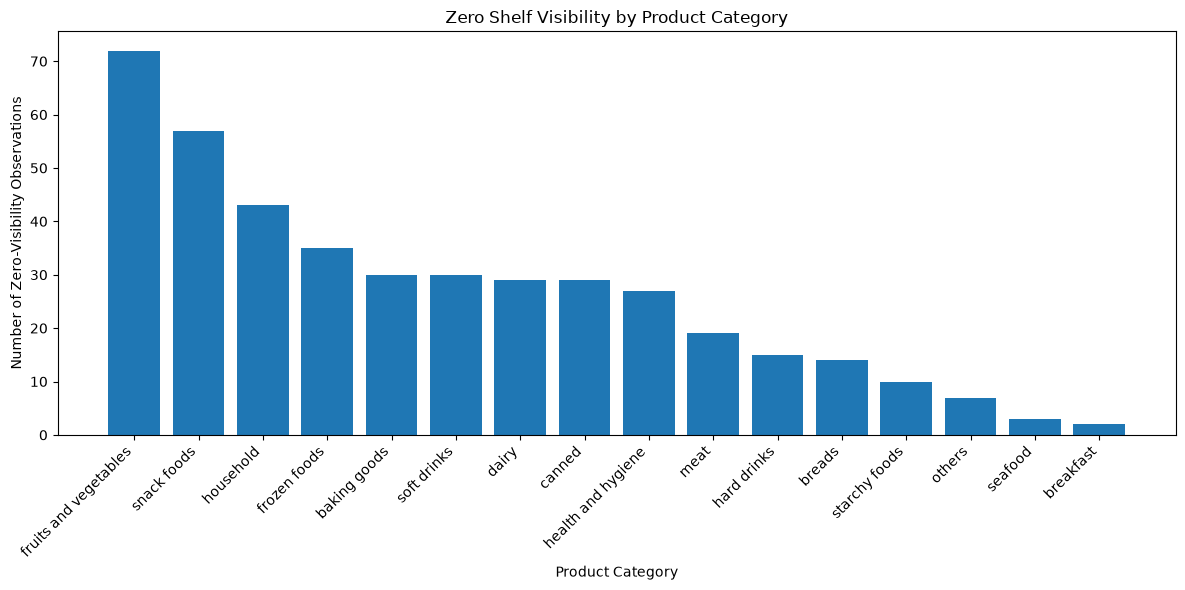

In [28]:
#Zero shelf visibility by product category

zero_visibility_by_category = (
    sales_record.loc[sales_record["shelf_visibility"] == 0, "product_category"]
      .str.strip()
      .str.lower()
      .value_counts()
      .sort_values(ascending=False)
)

print(zero_visibility_by_category)

plt.figure(figsize=(12, 6))

plt.bar(
    zero_visibility_by_category.index,
    zero_visibility_by_category.values
)

plt.title("Zero Shelf Visibility by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Zero-Visibility Observations")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [29]:
#percentage of each product category with zero shelf_visibility

zero_rate_by_category = (
    sales_record.groupby(
        sales_record["product_category"].str.strip().str.lower()
    )["shelf_visibility"]
    .apply(lambda x: (x == 0).mean() * 100)
    .sort_values(ascending=False)
)

print(zero_rate_by_category)

product_category
hard drinks              8.875740
starchy foods            8.849558
soft drinks              8.196721
fruits and vegetables    7.157058
breads                   6.698565
health and hygiene       6.553398
snack foods              6.109325
baking goods             5.813953
household                5.810811
seafood                  5.769231
canned                   5.609284
meat                     5.604720
others                   5.303030
dairy                    5.234657
frozen foods             5.185185
breakfast                2.352941
Name: shelf_visibility, dtype: float64


In [31]:
#product_weight_kg

print(sales_record["product_weight_kg"].describe())

count    5593.000000
mean       12.850876
std         4.646542
min         4.482000
25%         8.750000
50%        12.647000
75%        16.894000
max        21.883000
Name: product_weight_kg, dtype: float64


In [32]:
#product_weight missing information

missing_weight = sales_record["product_weight_kg"].isna().sum()
non_missing_weight = sales_record["product_weight_kg"].notna().sum()

print("Missing values:", missing_weight)
print("Non-missing values:", non_missing_weight)
print("Missing percentage:", missing_weight / len(sales_record) * 100)

Missing values: 1225
Non-missing values: 5593
Missing percentage: 17.967145790554415


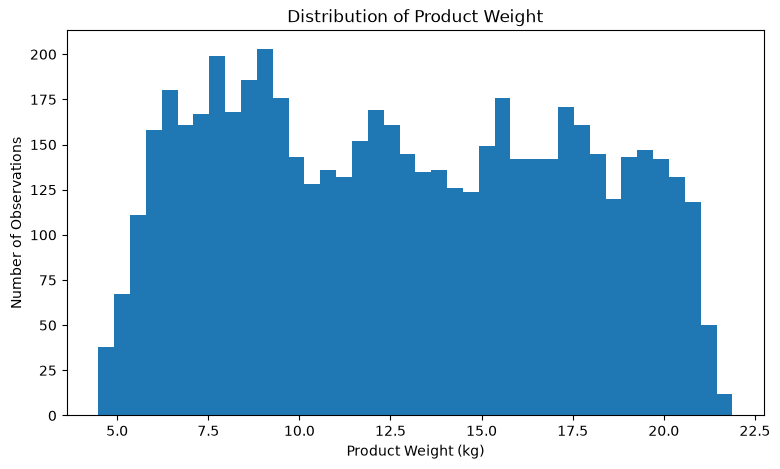

In [33]:
#distributions of the available product_weight

plt.figure(figsize=(9, 5))

plt.hist(
    sales_record["product_weight_kg"].dropna(),
    bins=40
)

plt.title("Distribution of Product Weight")
plt.xlabel("Product Weight (kg)")
plt.ylabel("Number of Observations")

plt.show()

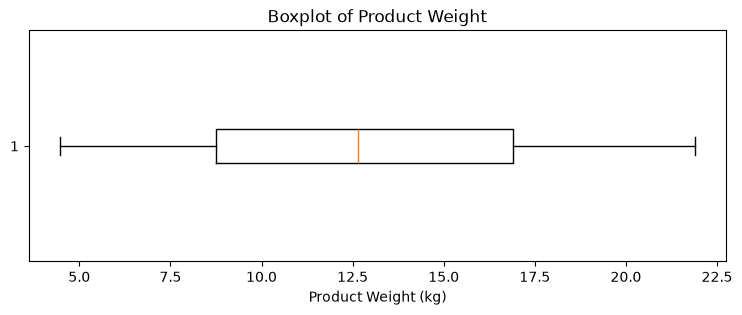

In [34]:
#product_weight potential extreme values

plt.figure(figsize=(9, 3))

plt.boxplot(
    sales_record["product_weight_kg"].dropna(),
    orientation="horizontal"
)

plt.title("Boxplot of Product Weight")
plt.xlabel("Product Weight (kg)")

plt.show()

store_code
STORE-7WS    748
STORE-T5G    427
STORE-AGY     10
STORE-89Z      9
STORE-YLW      8
STORE-HL7      8
STORE-9RG      7
STORE-DKU      5
STORE-OYG      3
Name: count, dtype: int64


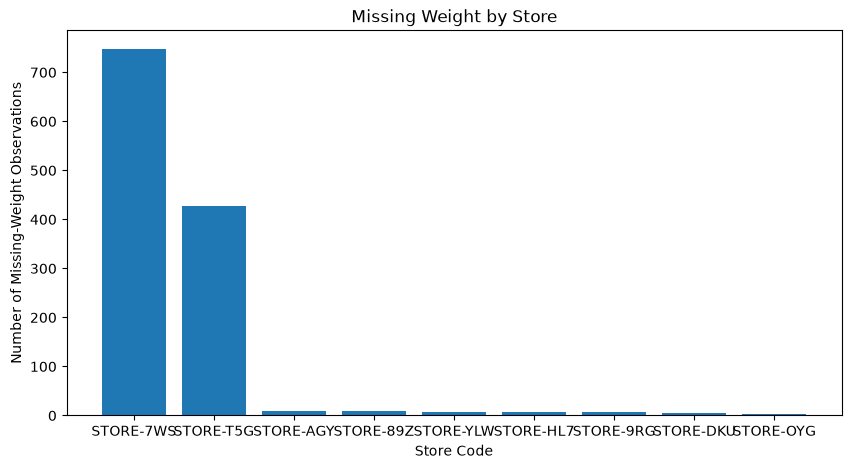

In [35]:
#product_weight missingness distribution across stores

missing_weight_by_store = (
    sales_record.loc[sales_record["product_weight_kg"].isna(), "store_code"]
      .value_counts()
)

print(missing_weight_by_store)


plt.figure(figsize=(10, 5))

plt.bar(
    missing_weight_by_store.index,
    missing_weight_by_store.values
)

plt.title("Missing Weight by Store")
plt.xlabel("Store Code")
plt.ylabel("Number of Missing-Weight Observations")

plt.show()

In [36]:
#percentage of each store with a missing product weight

missing_weight_rate_by_store = (
    sales_record.groupby("store_code")["product_weight_kg"]
      .apply(lambda x: x.isna().mean() * 100)
      .sort_values(ascending=False)
)

print(missing_weight_rate_by_store)

store_code
STORE-7WS    100.000000
STORE-T5G    100.000000
STORE-AGY      1.336898
STORE-89Z      1.236264
STORE-HL7      1.078167
STORE-YLW      1.061008
STORE-9RG      0.930851
STORE-DKU      0.679348
STORE-OYG      0.403226
STORE-JOR      0.000000
Name: product_weight_kg, dtype: float64


product_category
fruits and vegetables    186
snack foods              174
household                130
frozen foods             117
dairy                     96
canned                    91
baking goods              90
health and hygiene        75
meat                      66
soft drinks               65
breads                    45
hard drinks               24
others                    24
starchy foods             17
seafood                   13
breakfast                 12
Name: count, dtype: int64


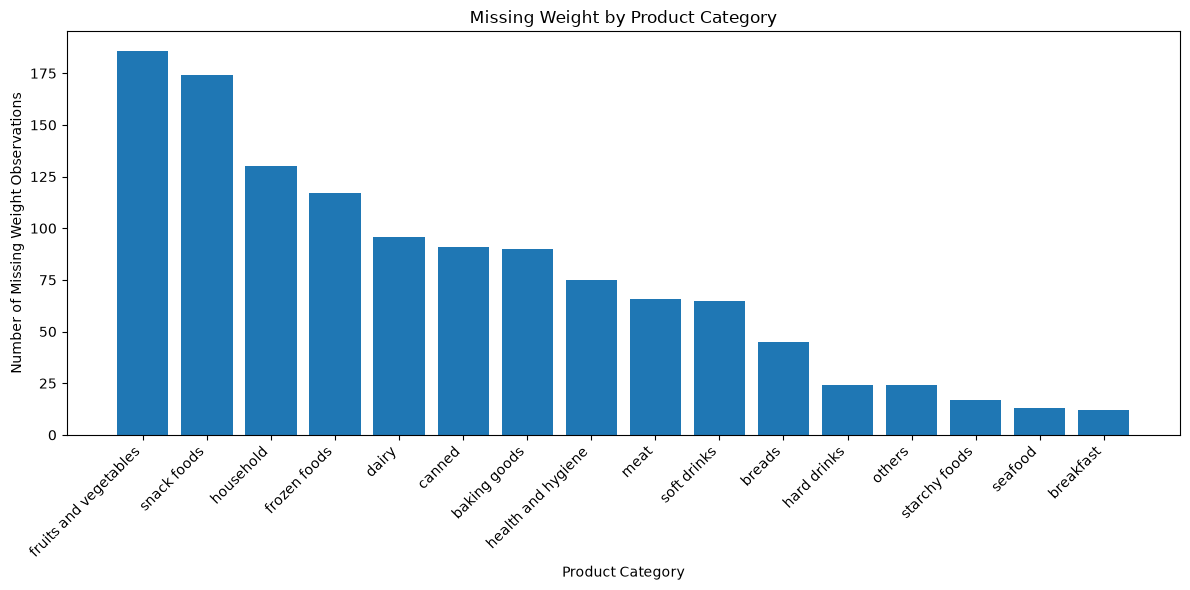

In [37]:
#missing product_weight in product_category

missing_weight_by_category = (
    sales_record.loc[sales_record["product_weight_kg"].isna(), "product_category"]
      .str.strip()
      .str.lower()
      .value_counts()
      .sort_values(ascending=False)
)

print(missing_weight_by_category)

plt.figure(figsize=(12, 6))

plt.bar(
    missing_weight_by_category.index,
    missing_weight_by_category.values
)

plt.title("Missing Weight by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Missing Weight Observations")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [38]:
# Percentage of each product_category with a missing weight

missing_weight_rate_by_category = (
    sales_record.groupby(
        sales_record["product_category"].str.strip().str.lower()
    )["product_weight_kg"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

print(missing_weight_rate_by_category)

product_category
seafood                  25.000000
breads                   21.531100
meat                     19.469027
snack foods              18.649518
fruits and vegetables    18.489066
health and hygiene       18.203883
others                   18.181818
soft drinks              17.759563
canned                   17.601547
household                17.567568
baking goods             17.441860
frozen foods             17.333333
dairy                    17.328520
starchy foods            15.044248
hard drinks              14.201183
breakfast                14.117647
Name: product_weight_kg, dtype: float64


In [39]:
#product_price

print(sales_record["product_price"].describe())

print("\nMissing values:")
print(sales_record["product_price"].isna().sum())

print("\nNumber of unique values:")
print(sales_record["product_price"].nunique())

count    6818.000000
mean      140.473623
std        62.413513
min        31.110000
25%        93.280000
50%       142.065000
75%       185.987500
max       273.040000
Name: product_price, dtype: float64

Missing values:
0

Number of unique values:
5818


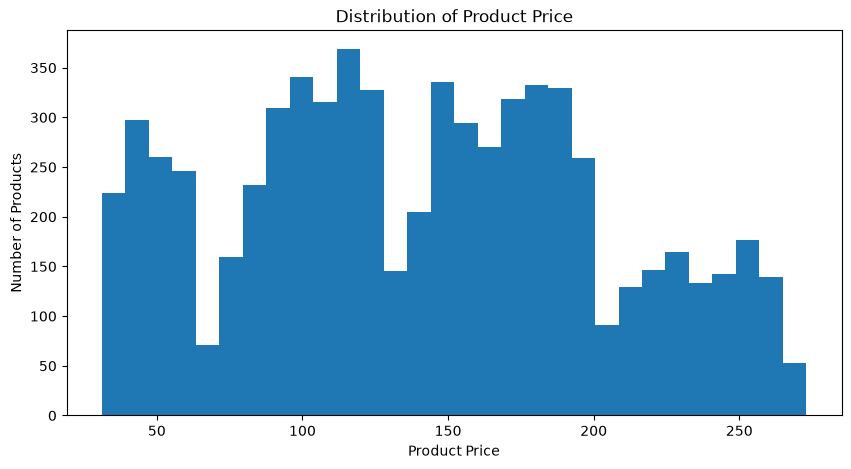

In [40]:
#distribution of product_price

plt.figure(figsize=(10, 5))

plt.hist(sales_record["product_price"], bins=30)

plt.xlabel("Product Price")
plt.ylabel("Number of Products")
plt.title("Distribution of Product Price")

plt.show()

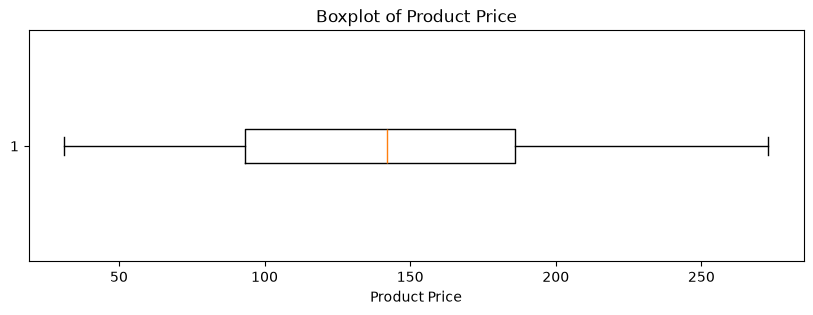

In [41]:
#product_price potential extreme values

plt.figure(figsize=(10, 3))

plt.boxplot(sales_record["product_price"], orientation="horizontal")

plt.xlabel("Product Price")
plt.title("Boxplot of Product Price")

plt.show()

In [42]:
#product_price distribution in percentile

print(
    sales_record["product_price"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00]
    )
)

0.00     31.1100
0.01     35.0421
0.05     42.1355
0.25     93.2800
0.50    142.0650
0.75    185.9875
0.95    250.1165
0.99    263.8530
1.00    273.0400
Name: product_price, dtype: float64


In [43]:
#store_age_years

print(sales_record["store_age_years"].describe())

print("\nMissing values:")
print(sales_record["store_age_years"].isna().sum())

print("\nNumber of unique values:")
print(sales_record["store_age_years"].nunique())

count    6818.000000
mean       34.178205
std         8.384574
min        23.000000
25%        28.000000
50%        33.000000
75%        45.000000
max        47.000000
Name: store_age_years, dtype: float64

Missing values:
0

Number of unique values:
9


store_age_years
23     742
25     744
28     752
30     736
33     728
34     439
35     754
45     748
47    1175
Name: count, dtype: int64


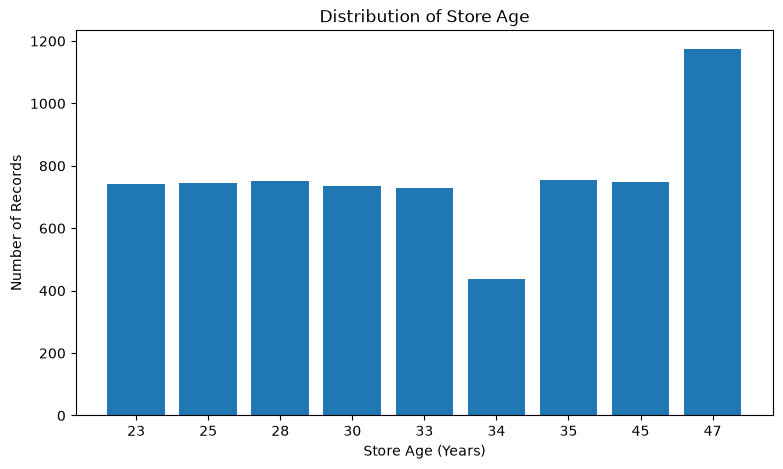

In [44]:
#store_age_year distribution

age_counts = sales_record["store_age_years"].value_counts().sort_index()

print(age_counts)

plt.figure(figsize=(9, 5))

plt.bar(age_counts.index.astype(str), age_counts.values)

plt.xlabel("Store Age (Years)")
plt.ylabel("Number of Records")
plt.title("Distribution of Store Age")

plt.show()

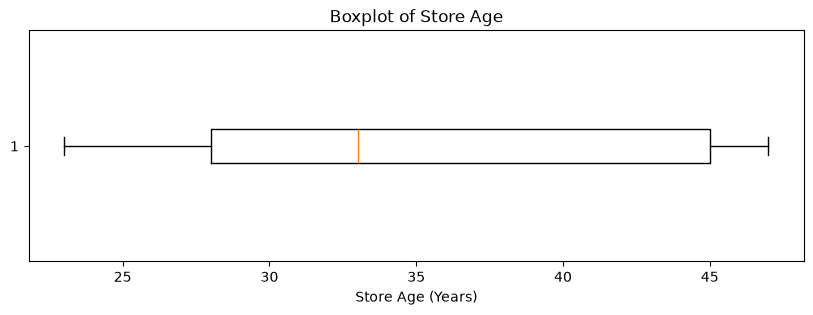

In [45]:
#store_age_years potential extreme value

plt.figure(figsize=(10, 3))

plt.boxplot(sales_record["store_age_years"], orientation="horizontal")

plt.xlabel("Store Age (Years)")
plt.title("Boxplot of Store Age")

plt.show()

In [46]:
#categorical features EDA

In [47]:
#fat_content

print("Unique values:")
print(sales_record["fat_content"].unique())

print("\nNumber of unique values:")
print(sales_record["fat_content"].nunique())

print("\nMissing values:")
print(sales_record["fat_content"].isna().sum())

print("\nCategory counts:")
print(sales_record["fat_content"].value_counts())

Unique values:
<StringArray>
['Low Fat', 'Regular']
Length: 2, dtype: str

Number of unique values:
2

Missing values:
0

Category counts:
fat_content
Low Fat    4425
Regular    2393
Name: count, dtype: int64


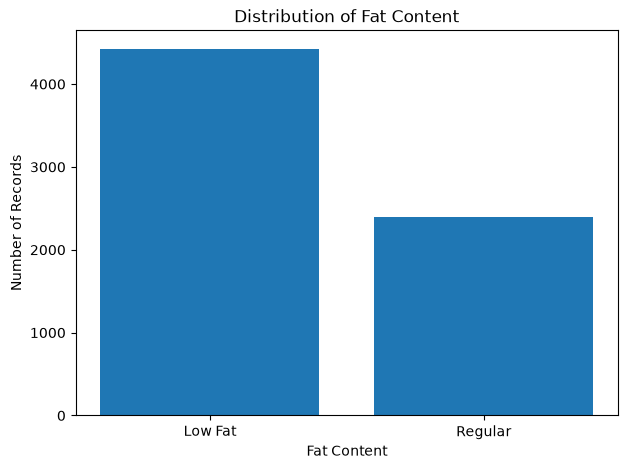

In [49]:
#distribution of fat content

fat_counts = sales_record["fat_content"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(fat_counts.index, fat_counts.values)

plt.xlabel("Fat Content")
plt.ylabel("Number of Records")
plt.title("Distribution of Fat Content")

plt.show()

In [50]:
#product_category

print("\nMissing values:")
print(sales_record["product_category"].isna().sum())

print("\nNumber of unique raw categories:")
print(sales_record["product_category"].nunique())

print("\nRaw categories:")
print(sorted(sales_record["product_category"].unique()))


Missing values:
0

Number of unique raw categories:
48

Raw categories:
['BAKING GOODS', 'BREADS', 'BREAKFAST', 'Baking Goods', 'Breads', 'Breakfast', 'CANNED', 'Canned', 'DAIRY', 'Dairy', 'FROZEN FOODS', 'FRUITS AND VEGETABLES', 'Frozen Foods', 'Fruits and Vegetables', 'HARD DRINKS', 'HEALTH AND HYGIENE', 'HOUSEHOLD', 'Hard Drinks', 'Health and Hygiene', 'Household', 'MEAT', 'Meat', 'OTHERS', 'Others', 'SEAFOOD', 'SNACK FOODS', 'SOFT DRINKS', 'STARCHY FOODS', 'Seafood', 'Snack Foods', 'Soft Drinks', 'Starchy Foods', 'baking goods', 'breads', 'breakfast', 'canned', 'dairy', 'frozen foods', 'fruits and vegetables', 'hard drinks', 'health and hygiene', 'household', 'meat', 'others', 'seafood', 'snack foods', 'soft drinks', 'starchy foods']


In [51]:
#How frequently does each raw category occur?

category_counts = sales_record["product_category"].value_counts()

print(category_counts)

product_category
Fruits and Vegetables    480
Snack Foods              468
Household                387
Frozen Foods             326
Canned                   271
Dairy                    269
fruits and vegetables    265
FRUITS AND VEGETABLES    261
Baking Goods             254
snack foods              236
SNACK FOODS              229
Health and Hygiene       197
HOUSEHOLD                185
Soft Drinks              178
frozen foods             177
FROZEN FOODS             172
household                168
Meat                     157
DAIRY                    143
dairy                    142
BAKING GOODS             137
canned                   129
baking goods             125
CANNED                   117
health and hygiene       116
Breads                   110
SOFT DRINKS              100
HEALTH AND HYGIENE        99
MEAT                      94
Hard Drinks               92
soft drinks               88
meat                      88
Others                    73
Starchy Foods             

In [52]:
normalized_category = (
    sales_record["product_category"]
    .str.strip()
    .str.lower()
)

print("Raw unique categories:", sales_record["product_category"].nunique())
print("Normalized unique categories:", normalized_category.nunique())

Raw unique categories: 48
Normalized unique categories: 16


product_category
fruits and vegetables    1006
snack foods               933
household                 740
frozen foods              675
dairy                     554
canned                    517
baking goods              516
health and hygiene        412
soft drinks               366
meat                      339
breads                    209
hard drinks               169
others                    132
starchy foods             113
breakfast                  85
seafood                    52
Name: count, dtype: int64


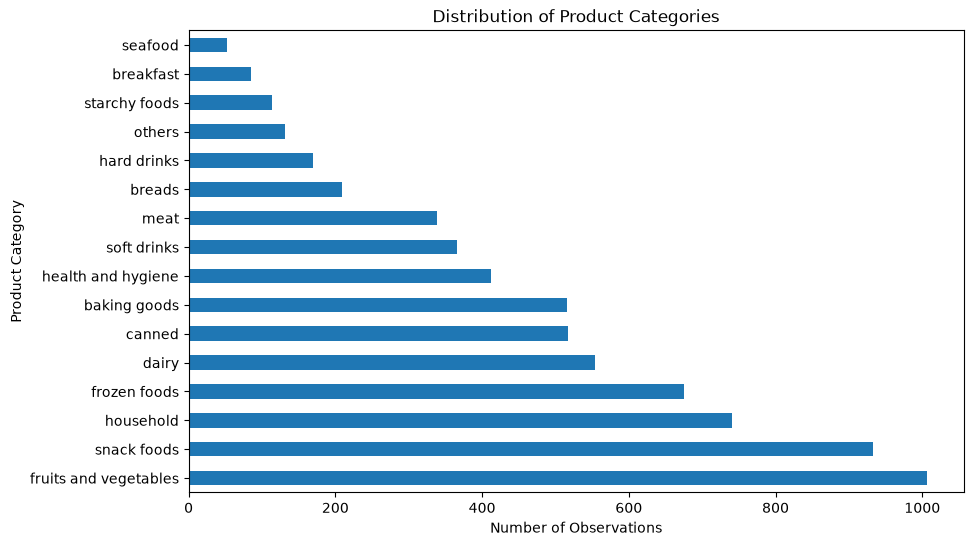

In [54]:
#How are observations distributed across the product categories?

category_counts = (
    sales_record["product_category"]
    .str.strip()
    .str.lower()
    .value_counts()
)

print(category_counts)

plt.figure(figsize=(10, 6))

category_counts.plot(kind="barh")

plt.title("Distribution of Product Categories")
plt.xlabel("Number of Observations")
plt.ylabel("Product Category")
plt.show()

Unique store codes:
<StringArray>
['STORE-AGY', 'STORE-YLW', 'STORE-89Z', 'STORE-7WS', 'STORE-9RG', 'STORE-HL7',
 'STORE-JOR', 'STORE-T5G', 'STORE-OYG', 'STORE-DKU']
Length: 10, dtype: str

Number of unique store codes:
10

Missing values:
0

Store code frequencies:
store_code
STORE-YLW    754
STORE-9RG    752
STORE-AGY    748
STORE-7WS    748
STORE-OYG    744
STORE-HL7    742
STORE-DKU    736
STORE-89Z    728
STORE-JOR    439
STORE-T5G    427
Name: count, dtype: int64


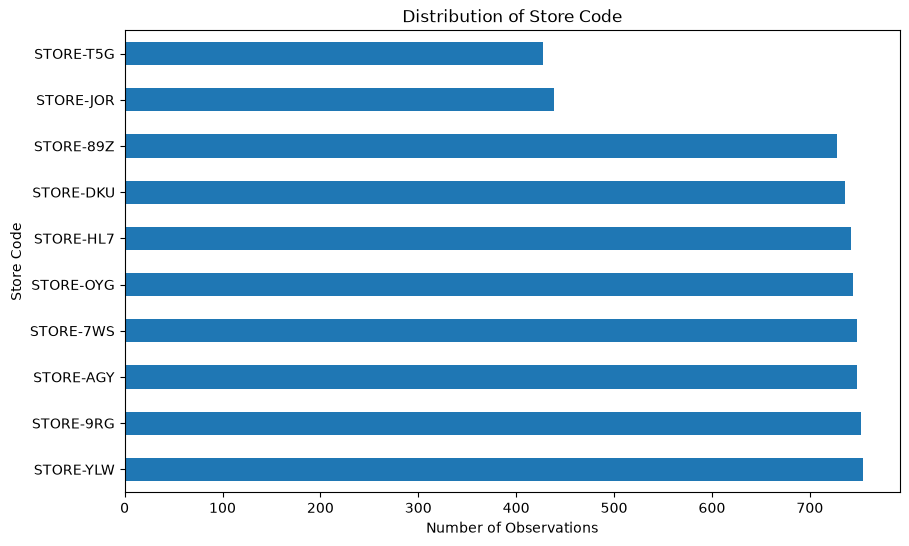

In [55]:
#store_code

print("Unique store codes:")
print(sales_record["store_code"].unique())

print("\nNumber of unique store codes:")
print(sales_record["store_code"].nunique())

print("\nMissing values:")
print(sales_record["store_code"].isna().sum())

print("\nStore code frequencies:")
print(sales_record["store_code"].value_counts())

store_code_counts = sales_record["store_code"].value_counts()

plt.figure(figsize=(10, 6))

store_code_counts.plot(kind="barh")

plt.title("Distribution of Store Code")
plt.xlabel("Number of Observations")
plt.ylabel("Store Code")
plt.show()

In [56]:
#store_size

print("Unique store sizes:")
print(sales_record["store_size"].unique())

print("\nNumber of unique store sizes:")
print(sales_record["store_size"].nunique())

print("\nMissing values:")
print(sales_record["store_size"].isna().sum())

print("\nStore size frequencies:")
print(sales_record["store_size"].value_counts(dropna=False))

Unique store sizes:
<StringArray>
['Large', 'Small', 'Medium', nan]
Length: 4, dtype: str

Number of unique store sizes:
3

Missing values:
1919

Store size frequencies:
store_size
Medium    2218
Small     1933
NaN       1919
Large      748
Name: count, dtype: int64


In [57]:
store_size_missing_by_store = (
    sales_record["store_size"]
    .isna()
    .groupby(sales_record["store_code"])
    .agg(["sum", "count"])
)

store_size_missing_by_store["missing_rate"] = (
    store_size_missing_by_store["sum"]
    / store_size_missing_by_store["count"]
    * 100
)

print(store_size_missing_by_store.sort_values("missing_rate", ascending=False))

            sum  count  missing_rate
store_code                          
STORE-JOR   439    439         100.0
STORE-DKU   736    736         100.0
STORE-OYG   744    744         100.0
STORE-7WS     0    748           0.0
STORE-89Z     0    728           0.0
STORE-9RG     0    752           0.0
STORE-HL7     0    742           0.0
STORE-AGY     0    748           0.0
STORE-T5G     0    427           0.0
STORE-YLW     0    754           0.0


In [58]:
print(
    sales_record.groupby("store_code", dropna=False)["store_size"]
    .value_counts(dropna=False)
)

store_code  store_size
STORE-7WS   Medium        748
STORE-89Z   Medium        728
STORE-9RG   Small         752
STORE-AGY   Large         748
STORE-DKU   NaN           736
STORE-HL7   Medium        742
STORE-JOR   NaN           439
STORE-OYG   NaN           744
STORE-T5G   Small         427
STORE-YLW   Small         754
Name: count, dtype: int64


In [59]:
#store_location_tier

print("Unique store location tiers:")
print(sales_record["store_location_tier"].unique())

print("\nNumber of unique tiers:")
print(sales_record["store_location_tier"].nunique())

print("\nMissing values:")
print(sales_record["store_location_tier"].isna().sum())

print("\nTier frequencies:")
print(sales_record["store_location_tier"].value_counts(dropna=False))

Unique store location tiers:
<StringArray>
['Tier_3', 'Tier_1', 'Tier_2']
Length: 3, dtype: str

Number of unique tiers:
3

Missing values:
0

Tier frequencies:
store_location_tier
Tier_3    2677
Tier_2    2232
Tier_1    1909
Name: count, dtype: int64


In [60]:
#store_format

print("Unique store formats:")
print(sales_record["store_format"].unique())

print("\nNumber of unique store formats:")
print(sales_record["store_format"].nunique())

print("\nMissing values:")
print(sales_record["store_format"].isna().sum())

print("\nStore format frequencies:")
print(sales_record["store_format"].value_counts(dropna=False))

Unique store formats:
<StringArray>
['Standard Supermarket', 'Flagship Hypermarket', 'Superstore', 'Corner Shop']
Length: 4, dtype: str

Number of unique store formats:
4

Missing values:
0

Store format frequencies:
store_format
Standard Supermarket    4462
Corner Shop              866
Flagship Hypermarket     748
Superstore               742
Name: count, dtype: int64


In [61]:
store_format_by_code = (
    sales_record.groupby("store_code")["store_format"]
    .nunique()
)

print(store_format_by_code)

store_code
STORE-7WS    1
STORE-89Z    1
STORE-9RG    1
STORE-AGY    1
STORE-DKU    1
STORE-HL7    1
STORE-JOR    1
STORE-OYG    1
STORE-T5G    1
STORE-YLW    1
Name: store_format, dtype: int64


In [62]:
print(
    sales_record[["store_code", "store_format"]]
    .drop_duplicates()
    .sort_values("store_code")
)

   store_code          store_format
3   STORE-7WS  Flagship Hypermarket
2   STORE-89Z  Standard Supermarket
4   STORE-9RG  Standard Supermarket
0   STORE-AGY  Standard Supermarket
14  STORE-DKU  Standard Supermarket
7   STORE-HL7            Superstore
9   STORE-JOR           Corner Shop
11  STORE-OYG  Standard Supermarket
10  STORE-T5G           Corner Shop
1   STORE-YLW  Standard Supermarket


In [63]:
#id

print("Data type:")
print(sales_record["id"].dtype)

print("\nNumber of unique IDs:")
print(sales_record["id"].nunique())

print("\nMissing values:")
print(sales_record["id"].isna().sum())

print("\nNumber of duplicated IDs:")
print(sales_record["id"].duplicated().sum())

print("\nSample IDs:")
print(sales_record["id"].head(10).to_list())

Data type:
str

Number of unique IDs:
6818

Missing values:
0

Number of duplicated IDs:
0

Sample IDs:
['row_00000', 'row_00001', 'row_00002', 'row_00003', 'row_00004', 'row_00005', 'row_00006', 'row_00007', 'row_00008', 'row_00010']


In [64]:
#product_code

print("Data type:")
print(sales_record["product_code"].dtype)

print("\nNumber of unique product codes:")
print(sales_record["product_code"].nunique())

print("\nNumber of duplicated product codes:")
print(sales_record["product_code"].duplicated().sum())

print("\nSample product codes:")
print(sales_record["product_code"].head(20).to_list())

Data type:
str

Number of unique product codes:
1555

Number of duplicated product codes:
5263

Sample product codes:
['PRD-PRFP9S', 'PRD-PXXK71', 'PRD-V5MOIJ', 'PRD-UN5Z3J', 'PRD-6RDQYB', 'PRD-E6VA05', 'PRD-MHLD93', 'PRD-EF6Y39', 'PRD-IAZMTU', 'PRD-DH2TA3', 'PRD-ONGWUL', 'PRD-UX01UP', 'PRD-741NWE', 'PRD-PGW90J', 'PRD-9USY38', 'PRD-GH9N12', 'PRD-HVVZBL', 'PRD-2CQ23Q', 'PRD-SUDBCI', 'PRD-5QVWC9']


In [65]:
product_frequency = sales_record["product_code"].value_counts()

print(product_frequency.describe())

print("\nFrequency distribution:")
print(product_frequency.value_counts().sort_index())

count    1555.000000
mean        4.384566
std         1.556328
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         9.000000
Name: count, dtype: float64

Frequency distribution:
count
1     46
2    140
3    251
4    394
5    351
6    240
7     97
8     35
9      1
Name: count, dtype: int64


In [66]:
print("Products appearing once:")
print(product_frequency[product_frequency == 1].shape[0])

print("\nMost frequently occurring products:")
print(product_frequency.head(10))

Products appearing once:
46

Most frequently occurring products:
product_code
PRD-YZB4K8    9
PRD-ONGWUL    8
PRD-SB61LG    8
PRD-U02KQN    8
PRD-N5F62D    8
PRD-1GXI9D    8
PRD-C2W953    8
PRD-1ZL2WT    8
PRD-T93K2H    8
PRD-V3EOYY    8
Name: count, dtype: int64


In [67]:
product_store_count = (
    sales_record.groupby("product_code")["store_code"]
    .nunique()
)

print(product_store_count.describe())

print("\nNumber of products by number of stores:")
print(product_store_count.value_counts().sort_index())

count    1555.000000
mean        4.384566
std         1.556328
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         9.000000
Name: store_code, dtype: float64

Number of products by number of stores:
store_code
1     46
2    140
3    251
4    394
5    351
6    240
7     97
8     35
9      1
Name: count, dtype: int64


In [68]:
#Relationship EDA

In [69]:
corr_matrix = sales_record.corr(numeric_only=True)
corr_matrix["total_sales"].sort_values(ascending=False)

total_sales          1.000000
product_price        0.569833
store_age_years      0.039443
product_weight_kg    0.015532
shelf_visibility    -0.118124
Name: total_sales, dtype: float64

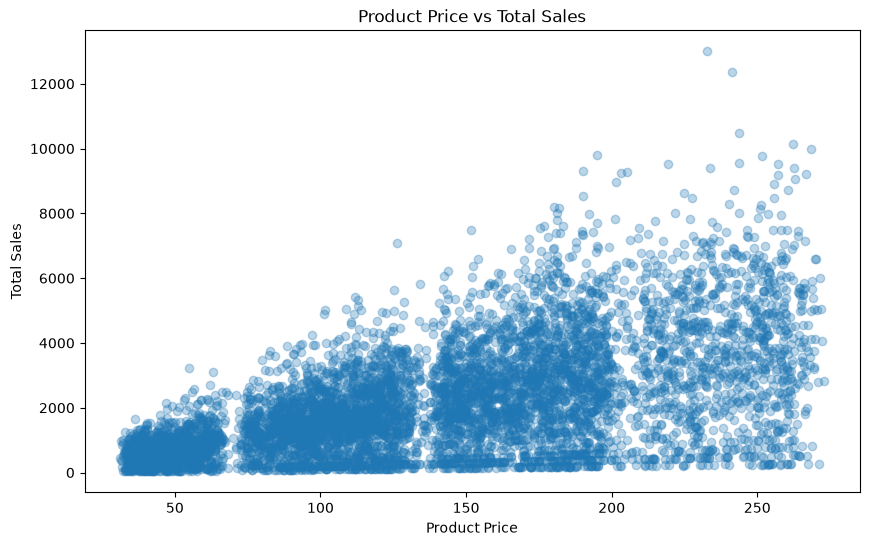

In [70]:
#product_price vs total_sales

plt.figure(figsize=(10, 6))

plt.scatter(
    sales_record["product_price"],
    sales_record["total_sales"],
    alpha=0.3
)

plt.xlabel("Product Price")
plt.ylabel("Total Sales")
plt.title("Product Price vs Total Sales")

plt.show()

In [71]:
price_bins = pd.qcut(
    sales_record["product_price"],
    q=10
)

price_sales_mean = (
    sales_record.groupby(price_bins, observed=True)["total_sales"]
      .mean()
      .reset_index()
)

price_sales_mean

,product_price,total_sales
0,"(31.108999999999998, 51.83]",625.416740
1,"(51.83, 83.752]",1030.650559
2,"(83.752, 101.463]",1446.364399
3,"(101.463, 117.848]",1674.543715
4,"(117.848, 142.065]",1953.847639
5,"(142.065, 158.83]",2299.528902
6,"(158.83, 177.744]",2704.116162
7,"(177.744, 194.228]",2901.120132
8,"(194.228, 230.835]",3304.609340
9,"(230.835, 273.04]",3809.192493


In [72]:
price_sales_mean["price_midpoint"] = (
    price_sales_mean["product_price"]
    .apply(lambda interval: interval.mid)
)

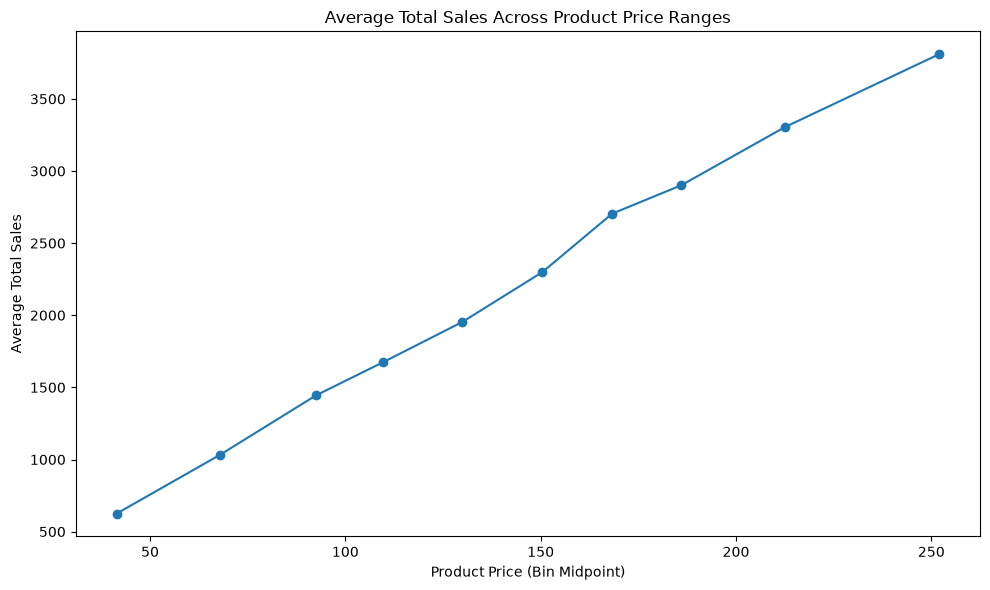

In [73]:
plt.figure(figsize=(10, 6))

plt.plot(
    price_sales_mean["price_midpoint"],
    price_sales_mean["total_sales"],
    marker="o"
)

plt.xlabel("Product Price (Bin Midpoint)")
plt.ylabel("Average Total Sales")
plt.title("Average Total Sales Across Product Price Ranges")

plt.tight_layout()
plt.show()

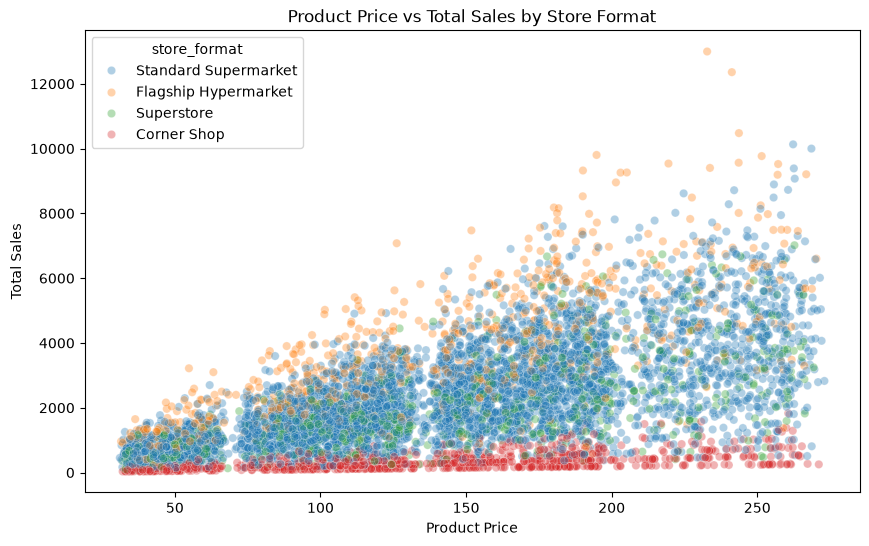

In [74]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sales_record,
    x="product_price",
    y="total_sales",
    hue="store_format",
    alpha=0.35
)

plt.xlabel("Product Price")
plt.ylabel("Total Sales")
plt.title("Product Price vs Total Sales by Store Format")

plt.show()

In [75]:
price_format_corr = (
    sales_record.groupby("store_format")
      .apply(
          lambda group: group["product_price"]
          .corr(group["total_sales"]),
          include_groups=False
      )
)

price_format_corr

store_format
Corner Shop             0.586538
Flagship Hypermarket    0.739044
Standard Supermarket    0.678111
Superstore              0.664365
dtype: float64

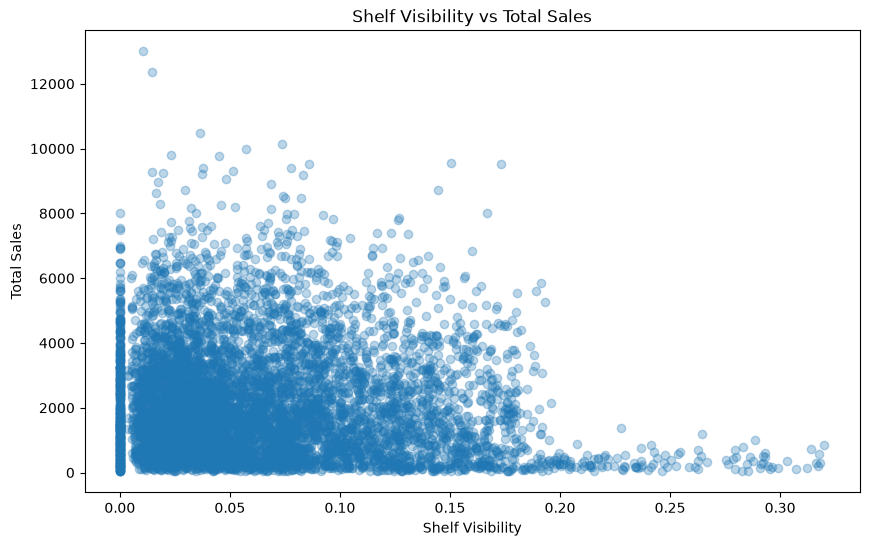

In [76]:
#shelf_visibility vs total_sales

plt.figure(figsize=(10, 6))

plt.scatter(
    sales_record["shelf_visibility"],
    sales_record["total_sales"],
    alpha=0.3
)

plt.xlabel("Shelf Visibility")
plt.ylabel("Total Sales")
plt.title("Shelf Visibility vs Total Sales")

plt.show()

In [77]:
visibility_bins = pd.qcut(
    sales_record["shelf_visibility"],
    q=10,
    duplicates="drop"
)

visibility_sales = (
    sales_record.groupby(visibility_bins, observed=True)["total_sales"]
      .agg(["mean", "median", "count"])
      .reset_index()
)

visibility_sales

,shelf_visibility,mean,median,count
0,"(-0.001, 0.0115]",2189.732577,1838.220,683
1,"(0.0115, 0.022]",2345.404604,1950.685,682
2,"(0.022, 0.0311]",2290.540557,2009.675,682
3,"(0.0311, 0.041]",2366.624275,1932.320,683
4,"(0.041, 0.0532]",2113.536003,1848.800,683
5,"(0.0532, 0.0674]",2171.124080,1762.760,679
6,"(0.0674, 0.0829]",2359.913426,1785.865,680
7,"(0.0829, 0.106]",2249.370292,1873.005,684
8,"(0.106, 0.14]",2067.929941,1727.510,680
9,"(0.14, 0.32]",1593.171378,1051.540,682


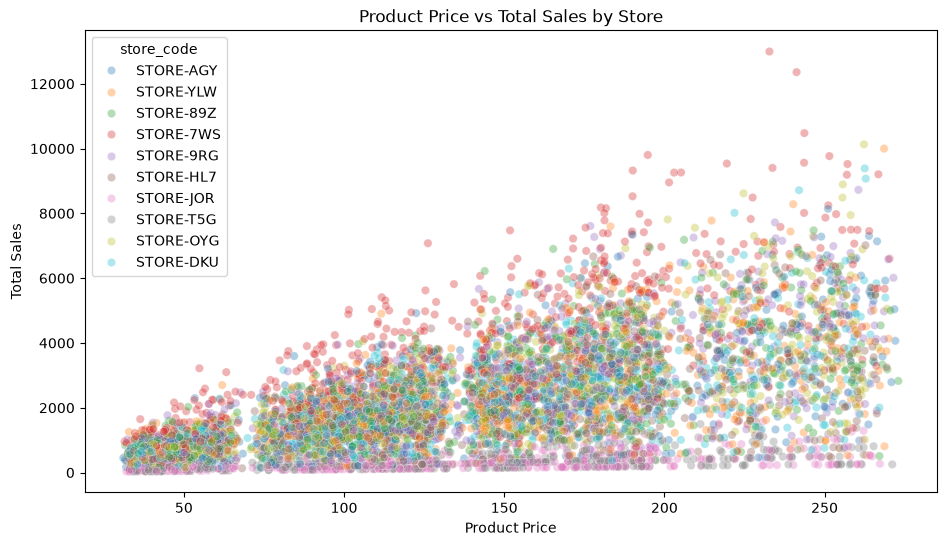

In [78]:
#store_code vs product_price

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=sales_record,
    x="product_price",
    y="total_sales",
    hue="store_code",
    alpha=0.35
)

plt.xlabel("Product Price")
plt.ylabel("Total Sales")
plt.title("Product Price vs Total Sales by Store")

plt.show()

In [79]:
price_store_corr = (
    sales_record.groupby("store_code")
      .apply(
          lambda group: group["product_price"]
          .corr(group["total_sales"]),
          include_groups=False
      )
)

price_store_corr

store_code
STORE-7WS    0.739044
STORE-89Z    0.698582
STORE-9RG    0.697980
STORE-AGY    0.706163
STORE-DKU    0.652420
STORE-HL7    0.664365
STORE-JOR    0.594396
STORE-OYG    0.684577
STORE-T5G    0.578749
STORE-YLW    0.630516
dtype: float64

In [80]:
#product_code vs total_sales

product_sales = (
    sales_record.groupby("product_code")["total_sales"]
      .agg(["mean", "median", "std", "count"])
      .sort_values("mean", ascending=False)
)

product_sales.head(20)

,mean,median,std,count
product_code,,,,
PRD-07NNDG,6524.425000,6524.425,3602.871685,2
PRD-5I78U5,6226.376667,5386.680,5758.912492,3
PRD-6LCP22,6093.525000,6093.525,1304.887783,2
PRD-UX01UP,6039.332500,5651.675,2170.256422,4
PRD-L7R843,5839.892500,5821.830,2220.781652,4
PRD-NZLAXA,5828.393333,5626.780,514.436743,3
PRD-DH02YH,5752.986667,6752.010,2205.589722,3
PRD-2G73AJ,5705.958000,6064.260,1182.467132,5
PRD-098QST,5655.613333,5535.330,718.466649,3


In [81]:
product_sales["mean"].describe()

count    1555.000000
mean     2187.320645
std      1187.454666
min        34.790000
25%      1232.316339
50%      2032.956667
75%      3017.923750
max      6524.425000
Name: mean, dtype: float64

In [82]:
product_sales["count"].value_counts().sort_index()

count
1     46
2    140
3    251
4    394
5    351
6    240
7     97
8     35
9      1
Name: count, dtype: int64

In [83]:
product_store = (
    sales_record.groupby(["store_code", "product_code"])["total_sales"]
      .agg(["mean", "count"])
)

product_store["mean"].describe()

count     6818.000000
mean      2174.756574
std       1697.894956
min         32.700000
25%        834.792500
50%       1790.890000
75%       3092.587500
max      12996.820000
Name: mean, dtype: float64

In [84]:
store_product_stats = (
    sales_record.groupby("store_code")["total_sales"]
      .agg(["mean", "std", "min", "max"])
)

store_product_stats

,mean,std,min,max
store_code,,,,
STORE-7WS,3660.182219,2070.097702,243.24,12996.82
STORE-89Z,2365.926745,1518.177714,155.47,7477.67
STORE-9RG,2479.168098,1553.797046,117.76,8726.50
STORE-AGY,2254.890120,1501.401983,72.28,8141.49
STORE-DKU,2177.136481,1446.586133,147.20,9388.15
STORE-HL7,1971.661954,1397.518220,73.54,7016.22
STORE-JOR,334.435011,275.205794,33.30,1830.37
STORE-OYG,2365.833656,1566.741909,149.73,10130.90
STORE-T5G,338.326651,254.819146,32.70,1523.62


In [85]:
#store_size vs total_sales

store_size_sales = (
    sales_record.groupby("store_size", dropna=False)["total_sales"]
      .agg(["mean", "median", "std", "count"])
      .sort_values("mean", ascending=False)
)

store_size_sales

,mean,median,std,count
store_size,,,,
Medium,2670.506826,2242.365,1837.626661,2218
Large,2254.890120,1998.725,1501.401983,748
Small,1918.405954,1557.960,1591.900156,1933
NaN,1828.749171,1463.670,1561.944991,1919


In [86]:
pd.crosstab(
    sales_record["store_code"],
    sales_record["store_size"],
    dropna=False
)

store_size,Large,Medium,Small,NaN
store_code,,,,
STORE-7WS,0,748,0,0
STORE-89Z,0,728,0,0
STORE-9RG,0,0,752,0
STORE-AGY,748,0,0,0
STORE-DKU,0,0,0,736
STORE-HL7,0,742,0,0
STORE-JOR,0,0,0,439
STORE-OYG,0,0,0,744
STORE-T5G,0,0,427,0


In [87]:
#product_category vs total_sales

sales_record["product_category"] = (
    sales_record["product_category"]
      .str.strip()
      .str.lower()
)

In [88]:
category_sales = (
    sales_record.groupby("product_category")["total_sales"]
      .agg(["mean", "median", "std", "count"])
      .sort_values("mean", ascending=False)
)

category_sales

,mean,median,std,count
product_category,,,,
starchy foods,2407.718584,2037.090,1738.033509,113
household,2292.464662,2023.745,1719.283849,740
fruits and vegetables,2277.854672,1816.565,1785.736216,1006
meat,2264.310383,1861.450,1759.505669,339
seafood,2262.524231,1929.040,1831.562938,52
dairy,2238.317076,1695.955,1841.244799,554
snack foods,2223.830568,1887.240,1629.473695,933
canned,2196.398743,1838.800,1618.732859,517
hard drinks,2189.723195,1842.880,1646.256984,169


In [89]:
# EDA Summary
#
# - The dataset has no duplicate rows, and most features are clean with no missing values
# - product_price has a strong positive relationship with total_sales, and this relationship
#   remains positive within individual stores
# - store_code has a strong effect on sales, with large differences in average sales between stores
# - There is also substantial variation in sales within each store, suggesting that product-level
#   information is important
# - product_code shows meaningful differences in average sales across products
# - product_category shows some variation in sales and can provide broader product information
# - store_size is related to sales, but it is completely determined by store_code
# - store_format is also completely determined by store_code
# - store_location_tier has some relationship with sales but is weaker than store_code
# - shelf_visibility has a weak and nonlinear relationship with sales; zero values appear valid
# - fat_content, store_age_years, and product_weight_kg show relatively weak direct relationships
#   with sales
# - Missing values in product_weight_kg and store_size are structured by store
# - total_sales is right-skewed with some high values

In [3]:
#feature engineering & modeling

In [4]:
from sklearn.model_selection import KFold

X = sales_record.drop(columns=["total_sales", "id"]).copy()
y = sales_record["total_sales"].copy()

cat_features = [
    "product_code",
    "fat_content",
    "product_category",
    "store_code",
    "store_size",
    "store_location_tier",
    "store_format"
]

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [5]:
X["product_category"] = (
    X["product_category"]
    .str.strip()
    .str.lower()
)

In [8]:
#Testing CatBoost
#I let CatBoost handle numerical missing values natively

from catboost import CatBoostRegressor
from sklearn.metrics import root_mean_squared_error

fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X), start=1):

    X_train = X.iloc[train_idx].copy()
    X_valid = X.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    for col in cat_features:
        X_train[col] = X_train[col].fillna("__MISSING__").astype(str)
        X_valid[col] = X_valid[col].fillna("__MISSING__").astype(str)

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features
    )

    predictions = model.predict(X_valid)

    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print("\nMean RMSE:", np.mean(fold_rmse))
print("Std RMSE:", np.std(fold_rmse))

Fold 1: RMSE = 1080.3847
Fold 2: RMSE = 1060.4457
Fold 3: RMSE = 1096.3032
Fold 4: RMSE = 1115.2318
Fold 5: RMSE = 1074.8086

Mean RMSE: 1085.4347800484034
Std RMSE: 18.808809955950668


In [114]:
#I created my own custom transformer to handle the missing values
#I filled misssing product_weight using that product's own median weight 
#and will only fall back to the overall median if a product had zero known weight anywhere. 
#store_size was similar. I filled it using that store's own most common value first, global fallback second

from sklearn.base import BaseEstimator, TransformerMixin

class GroupBasedImputer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X = X.copy()

        self.product_weight_medians_ = (
            X.groupby("product_code")["product_weight_kg"]
            .median()
        )

        self.weight_fallback_ = X["product_weight_kg"].median()

        self.store_size_modes_ = (
            X.groupby("store_code")["store_size"]
            .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
        )

        self.size_fallback_ = X["store_size"].mode().iloc[0]

        return self

    def transform(self, X):
        X = X.copy()

        X["product_weight_kg"] = (
            X["product_weight_kg"]
            .fillna(
                X["product_code"].map(
                    self.product_weight_medians_
                )
            )
            .fillna(self.weight_fallback_)
        )

        X["store_size"] = (
            X["store_size"]
            .fillna(
                X["store_code"].map(
                    self.store_size_modes_
                )
            )
            .fillna(self.size_fallback_)
        )

        return X

In [115]:
fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X), start=1):

    X_train = X.iloc[train_idx].copy()
    X_valid = X.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    imputer = GroupBasedImputer()
    X_train = imputer.fit_transform(X_train)
    X_valid = imputer.transform(X_valid)

    for col in cat_features:
        X_train[col] = X_train[col].fillna("__MISSING__").astype(str)
        X_valid[col] = X_valid[col].fillna("__MISSING__").astype(str)

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features
    )

    predictions = model.predict(X_valid)

    rmse = root_mean_squared_error(
        y_valid,
        predictions
    )

    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print("\nMean RMSE:", np.mean(fold_rmse))
print("Std RMSE:", np.std(fold_rmse))

Fold 1: RMSE = 1082.0678
Fold 2: RMSE = 1053.6189
Fold 3: RMSE = 1091.5995
Fold 4: RMSE = 1115.9168
Fold 5: RMSE = 1081.8125

Mean RMSE: 1085.0030873678284
Std RMSE: 20.01466558761083


In [116]:
#Testing Missingness indicator

X_missing = X.copy()

X_missing["product_weight_missing"] = (
    X_missing["product_weight_kg"].isna().astype(int)
)

X_missing["store_size_missing"] = (
    X_missing["store_size"].isna().astype(int)
)

In [117]:
fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_missing), start=1):

    X_train = X_missing.iloc[train_idx].copy()
    X_valid = X_missing.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    for col in cat_features:
        X_train[col] = X_train[col].fillna("__MISSING__").astype(str)
        X_valid[col] = X_valid[col].fillna("__MISSING__").astype(str)

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features
    )

    predictions = model.predict(X_valid)

    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")

Fold 1: RMSE = 1078.6128
Fold 2: RMSE = 1060.3646
Fold 3: RMSE = 1093.2425
Fold 4: RMSE = 1113.8170
Fold 5: RMSE = 1075.3276

Mean RMSE: 1084.2729
Std RMSE: 18.0940


In [120]:
#Testing log_product_price

X_log_price = X.copy()

X_log_price["product_weight_missing"] = (
    X_log_price["product_weight_kg"].isna().astype(int)
)

X_log_price["store_size_missing"] = (
    X_log_price["store_size"].isna().astype(int)
)


X_log_price["log_product_price"] = np.log1p(
    X_log_price["product_price"]
)

In [119]:
fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_log_price), start=1):

    X_train = X_log_price.iloc[train_idx].copy()
    X_valid = X_log_price.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    for col in cat_features:
        X_train[col] = X_train[col].fillna("__MISSING__").astype(str)
        X_valid[col] = X_valid[col].fillna("__MISSING__").astype(str)

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features
    )

    predictions = model.predict(X_valid)

    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")

Fold 1: RMSE = 1077.6369
Fold 2: RMSE = 1059.9690
Fold 3: RMSE = 1093.5638
Fold 4: RMSE = 1117.7687
Fold 5: RMSE = 1086.6492

Mean RMSE: 1087.1175
Std RMSE: 19.0168


In [121]:
#Testing categorical interaction(store x product category)

X_interaction = X.copy()

X_interaction["product_weight_missing"] = (
    X_interaction["product_weight_kg"].isna().astype(int)
)

X_interaction["store_size_missing"] = (
    X_interaction["store_size"].isna().astype(int)
)

X_interaction["store_category"] = (
    X_interaction["store_code"].astype(str)
    + "_"
    + X_interaction["product_category"].astype(str)
)

cat_features_interaction = cat_features + ["store_category"]

In [128]:
fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_interaction), start=1):

    X_train = X_interaction.iloc[train_idx].copy()
    X_valid = X_interaction.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    for col in cat_features:
        X_train[col] = X_train[col].fillna("__MISSING__").astype(str)
        X_valid[col] = X_valid[col].fillna("__MISSING__").astype(str)

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )
    model.fit(
        X_train,
        y_train,
        cat_features=cat_features_interaction
    )

    predictions = model.predict(X_valid)

    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print("\nMean RMSE:", np.mean(fold_rmse))
print("Std RMSE:", np.std(fold_rmse))

Fold 1: RMSE = 1080.9944
Fold 2: RMSE = 1062.0797
Fold 3: RMSE = 1102.9639
Fold 4: RMSE = 1118.1357
Fold 5: RMSE = 1080.3708

Mean RMSE: 1088.908892258415
Std RMSE: 19.529936787003397


In [124]:
#Testing lightgbm

X_lgb = X.copy()

X_lgb["product_weight_missing"] = (
    X_lgb["product_weight_kg"].isna().astype(int)
)
X_lgb["store_size_missing"] = (
    X_lgb["store_size"].isna().astype(int)
)

cat_features_lgb = [
    "product_code",
    "fat_content",
    "product_category",
    "store_code",
    "store_size",
    "store_location_tier",
    "store_format"
]

#explicit categorical missing value
for col in cat_features_lgb:
    X_lgb[col] = X_lgb[col].astype("category")

In [129]:
from lightgbm import LGBMRegressor

fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_lgb), start=1):

    X_train = X_lgb.iloc[train_idx].copy()
    X_valid = X_lgb.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    model = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        objective="regression",
        random_state=42,
        verbosity=-1
    )

    model.fit(
        X_train,
        y_train,
        categorical_feature=cat_features_lgb
    )

    predictions = model.predict(X_valid)

    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")

Fold 1: RMSE = 1144.9909
Fold 2: RMSE = 1098.0005
Fold 3: RMSE = 1141.1925
Fold 4: RMSE = 1171.6084
Fold 5: RMSE = 1127.7572

Mean RMSE: 1136.7099
Std RMSE: 24.0214


In [6]:
#Tuning the catboost model to find best hyperparameters

from sklearn.model_selection import ParameterSampler

param_distributions = {
    "depth": [4, 5, 6, 7, 8, 9, 10],
    "learning_rate": [0.02, 0.03, 0.05, 0.07, 0.10],
    "l2_leaf_reg": [1, 3, 5, 7, 10],
    "iterations": [300, 500, 700, 1000],
    "random_strength": [0, 0.5, 1, 2],
    "bagging_temperature": [0, 0.5, 1, 2],
}

search_params = list(
    ParameterSampler(
        param_distributions,
        n_iter=30,
        random_state=42
    )
)

In [7]:
X_tune = X.copy()

X_tune["product_weight_missing"] = (
    X_tune["product_weight_kg"].isna().astype(int)
)

X_tune["store_size_missing"] = (
    X_tune["store_size"].isna().astype(int)
)

In [8]:
cat_features = [
    "product_code",
    "fat_content",
    "product_category",
    "store_code",
    "store_size",
    "store_location_tier",
    "store_format"
]

In [9]:
results = []

for trial, params in enumerate(search_params, start=1):

    fold_rmse = []

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X_tune), start=1
    ):

        X_train = X_tune.iloc[train_idx].copy()
        X_valid = X_tune.iloc[valid_idx].copy()

        y_train = y.iloc[train_idx]
        y_valid = y.iloc[valid_idx]

        
        for col in cat_features:
            X_train[col] = (
                X_train[col]
                .fillna("__MISSING__")
                .astype(str)
            )

            X_valid[col] = (
                X_valid[col]
                .fillna("__MISSING__")
                .astype(str)
            )

        model = CatBoostRegressor(
            **params,
            loss_function="RMSE",
            random_seed=42,
            verbose=False
        )

        model.fit(
            X_train,
            y_train,
            cat_features=cat_features
        )

        predictions = model.predict(X_valid)

        rmse = root_mean_squared_error(
            y_valid,
            predictions
        )

        fold_rmse.append(rmse)

    mean_rmse = np.mean(fold_rmse)
    std_rmse = np.std(fold_rmse)

    results.append({
        "trial": trial,
        **params,
        "mean_rmse": mean_rmse,
        "std_rmse": std_rmse
    })

    print(
        f"Trial {trial:02d}/30 | "
        f"RMSE: {mean_rmse:.4f} | {std_rmse:.4f} | "
        f"{params}"
    )

Trial 01/30 | RMSE: 1079.8651 | 20.4917 | {'random_strength': 1, 'learning_rate': 0.05, 'l2_leaf_reg': 7, 'iterations': 300, 'depth': 8, 'bagging_temperature': 1}
Trial 02/30 | RMSE: 1078.2445 | 20.6491 | {'random_strength': 0, 'learning_rate': 0.02, 'l2_leaf_reg': 7, 'iterations': 300, 'depth': 6, 'bagging_temperature': 0}
Trial 03/30 | RMSE: 1088.8661 | 20.7032 | {'random_strength': 1, 'learning_rate': 0.05, 'l2_leaf_reg': 10, 'iterations': 500, 'depth': 10, 'bagging_temperature': 0.5}
Trial 04/30 | RMSE: 1101.6533 | 17.4790 | {'random_strength': 2, 'learning_rate': 0.05, 'l2_leaf_reg': 10, 'iterations': 1000, 'depth': 9, 'bagging_temperature': 0.5}
Trial 05/30 | RMSE: 1086.8564 | 19.0033 | {'random_strength': 1, 'learning_rate': 0.07, 'l2_leaf_reg': 3, 'iterations': 500, 'depth': 4, 'bagging_temperature': 1}
Trial 06/30 | RMSE: 1078.7745 | 19.7426 | {'random_strength': 0.5, 'learning_rate': 0.03, 'l2_leaf_reg': 7, 'iterations': 700, 'depth': 5, 'bagging_temperature': 1}
Trial 07/30 

In [10]:
results_table = (
    pd.DataFrame(results)
    .sort_values("mean_rmse")
    .reset_index(drop=True)
)

results_table.head(10)

,trial,random_strength,learning_rate,l2_leaf_reg,iterations,depth,bagging_temperature,mean_rmse,std_rmse
0,7,1.0,0.03,7,300,5,0.0,1075.925467,19.896859
1,29,2.0,0.03,5,300,9,0.0,1076.542555,19.768878
2,22,0.5,0.03,10,500,5,0.5,1076.873829,19.692197
3,14,2.0,0.02,10,500,9,2.0,1077.604179,19.880880
4,25,1.0,0.03,7,700,4,2.0,1077.792518,20.178944
5,2,0.0,0.02,7,300,6,0.0,1078.244501,20.649073
6,19,0.0,0.02,3,300,6,1.0,1078.620425,19.957531
7,6,0.5,0.03,7,700,5,1.0,1078.774458,19.742619
8,12,0.5,0.03,10,300,8,0.0,1079.468270,19.917733
9,1,1.0,0.05,7,300,8,1.0,1079.865135,20.491673


In [11]:
results_table[
    [
        "trial",
        "mean_rmse",
        "std_rmse",
        "depth",
        "learning_rate",
        "iterations",
        "l2_leaf_reg",
        "random_strength",
        "bagging_temperature"
    ]
].head(10)

,trial,mean_rmse,std_rmse,depth,learning_rate,iterations,l2_leaf_reg,random_strength,bagging_temperature
0,7,1075.925467,19.896859,5,0.03,300,7,1.0,0.0
1,29,1076.542555,19.768878,9,0.03,300,5,2.0,0.0
2,22,1076.873829,19.692197,5,0.03,500,10,0.5,0.5
3,14,1077.604179,19.880880,9,0.02,500,10,2.0,2.0
4,25,1077.792518,20.178944,4,0.03,700,7,1.0,2.0
5,2,1078.244501,20.649073,6,0.02,300,7,0.0,0.0
6,19,1078.620425,19.957531,6,0.02,300,3,0.0,1.0
7,6,1078.774458,19.742619,5,0.03,700,7,0.5,1.0
8,12,1079.468270,19.917733,8,0.03,300,10,0.5,0.0
9,1,1079.865135,20.491673,8,0.05,300,7,1.0,1.0


In [137]:
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import root_mean_squared_error

param_distributions_2 = {
    "depth": [4, 5, 6, 7, 8, 9],
    "learning_rate": [0.02, 0.025, 0.03, 0.035, 0.04],
    "iterations": [250, 300, 400, 500, 600, 700],
    "l2_leaf_reg": [5, 7, 10, 12],
    "random_strength": [0, 0.5, 1, 1.5, 2],
    "bagging_temperature": [0, 0.5, 1, 2],
}

search_params_2 = list(
    ParameterSampler(
        param_distributions_2,
        n_iter=30,
        random_state=43
    )
)

y = sales_record["total_sales"].copy()

In [138]:
results = []

for trial, params in enumerate(search_params_2, start=1):

    fold_rmse = []

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X_tune), start=1
    ):

        X_train = X_tune.iloc[train_idx].copy()
        X_valid = X_tune.iloc[valid_idx].copy()

        y_train = y.iloc[train_idx]
        y_valid = y.iloc[valid_idx]

        
        for col in cat_features:
            X_train[col] = (
                X_train[col]
                .fillna("__MISSING__")
                .astype(str)
            )

            X_valid[col] = (
                X_valid[col]
                .fillna("__MISSING__")
                .astype(str)
            )

        model = CatBoostRegressor(
            **params,
            loss_function="RMSE",
            random_seed=42,
            verbose=False
        )

        model.fit(
            X_train,
            y_train,
            cat_features=cat_features
        )

        predictions = model.predict(X_valid)

        rmse = root_mean_squared_error(
            y_valid,
            predictions
        )

        fold_rmse.append(rmse)

    mean_rmse = np.mean(fold_rmse)
    std_rmse = np.std(fold_rmse)

    results.append({
        "trial": trial,
        **params,
        "mean_rmse": mean_rmse,
        "std_rmse": std_rmse
    })

    print(
        f"Trial {trial:02d}/30 | "
        f"RMSE: {mean_rmse:.4f} | {std_rmse:.4f} | "
        f"{params}"
    )

Trial 01/30 | RMSE: 1086.2569 | 20.4754 | {'random_strength': 1.5, 'learning_rate': 0.04, 'l2_leaf_reg': 7, 'iterations': 500, 'depth': 9, 'bagging_temperature': 2}
Trial 02/30 | RMSE: 1081.8371 | 20.2583 | {'random_strength': 1, 'learning_rate': 0.035, 'l2_leaf_reg': 12, 'iterations': 500, 'depth': 9, 'bagging_temperature': 0}
Trial 03/30 | RMSE: 1079.0472 | 19.3471 | {'random_strength': 1.5, 'learning_rate': 0.02, 'l2_leaf_reg': 5, 'iterations': 700, 'depth': 7, 'bagging_temperature': 0}
Trial 04/30 | RMSE: 1077.9276 | 20.1909 | {'random_strength': 0, 'learning_rate': 0.03, 'l2_leaf_reg': 12, 'iterations': 300, 'depth': 5, 'bagging_temperature': 1}
Trial 05/30 | RMSE: 1083.6768 | 18.6558 | {'random_strength': 1, 'learning_rate': 0.035, 'l2_leaf_reg': 5, 'iterations': 500, 'depth': 9, 'bagging_temperature': 1}
Trial 06/30 | RMSE: 1084.9957 | 20.7266 | {'random_strength': 2, 'learning_rate': 0.035, 'l2_leaf_reg': 12, 'iterations': 700, 'depth': 9, 'bagging_temperature': 2}
Trial 07/30 

In [139]:
results_table_2 = (
    pd.DataFrame(results)
    .sort_values("mean_rmse")
    .reset_index(drop=True)
)

results_table_2.head(10)

,trial,random_strength,learning_rate,l2_leaf_reg,iterations,depth,bagging_temperature,mean_rmse,std_rmse
0,19,2.0,0.020,12,500,4,0.0,1074.895526,19.581375
1,8,2.0,0.040,12,250,6,1.0,1075.003946,19.651689
2,13,2.0,0.025,7,300,7,0.5,1075.429218,19.773622
3,28,1.0,0.025,7,300,4,0.0,1075.682128,19.533851
4,17,2.0,0.025,10,300,6,2.0,1075.982959,18.923586
5,15,1.5,0.025,5,250,7,2.0,1076.152949,20.508605
6,27,2.0,0.040,7,300,6,2.0,1076.233249,21.711690
7,25,0.5,0.025,5,300,5,0.0,1076.775129,19.825545
8,7,2.0,0.030,10,400,7,0.0,1076.933605,20.385127
9,18,1.5,0.040,12,400,5,2.0,1077.310554,19.341325


In [140]:
results_table_2[
    [
        "trial",
        "mean_rmse",
        "std_rmse",
        "depth",
        "learning_rate",
        "iterations",
        "l2_leaf_reg",
        "random_strength",
        "bagging_temperature"
    ]
].head(10)

,trial,mean_rmse,std_rmse,depth,learning_rate,iterations,l2_leaf_reg,random_strength,bagging_temperature
0,19,1074.895526,19.581375,4,0.020,500,12,2.0,0.0
1,8,1075.003946,19.651689,6,0.040,250,12,2.0,1.0
2,13,1075.429218,19.773622,7,0.025,300,7,2.0,0.5
3,28,1075.682128,19.533851,4,0.025,300,7,1.0,0.0
4,17,1075.982959,18.923586,6,0.025,300,10,2.0,2.0
5,15,1076.152949,20.508605,7,0.025,250,5,1.5,2.0
6,27,1076.233249,21.711690,6,0.040,300,7,2.0,2.0
7,25,1076.775129,19.825545,5,0.025,300,5,0.5,0.0
8,7,1076.933605,20.385127,7,0.030,400,10,2.0,0.0
9,18,1077.310554,19.341325,5,0.040,400,12,1.5,2.0


In [17]:
param_distributions_3 = {
    "depth": [4, 5, 6, 7],
    "learning_rate": [0.015, 0.02, 0.025, 0.03, 0.035],
    "iterations": [300, 400, 500, 600, 700],
    "l2_leaf_reg": [7, 10, 12, 15],
    "random_strength": [1, 1.5, 2, 2.5, 3],
    "bagging_temperature": [0, 0.5, 1, 2],
}

search_params_3 = list(
    ParameterSampler(
        param_distributions_3,
        n_iter=30,
        random_state=44
    )
)


In [18]:
results = []

for trial, params in enumerate(search_params_3, start=1):

    fold_rmse = []

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X_tune), start=1
    ):

        X_train = X_tune.iloc[train_idx].copy()
        X_valid = X_tune.iloc[valid_idx].copy()

        y_train = y.iloc[train_idx]
        y_valid = y.iloc[valid_idx]

        
        for col in cat_features:
            X_train[col] = (
                X_train[col]
                .fillna("__MISSING__")
                .astype(str)
            )

            X_valid[col] = (
                X_valid[col]
                .fillna("__MISSING__")
                .astype(str)
            )

        model = CatBoostRegressor(
            **params,
            loss_function="RMSE",
            random_seed=42,
            verbose=False
        )

        model.fit(
            X_train,
            y_train,
            cat_features=cat_features
        )

        predictions = model.predict(X_valid)

        rmse = root_mean_squared_error(
            y_valid,
            predictions
        )

        fold_rmse.append(rmse)

    mean_rmse = np.mean(fold_rmse)
    std_rmse = np.std(fold_rmse)

    results.append({
        "trial": trial,
        **params,
        "mean_rmse": mean_rmse,
        "std_rmse": std_rmse
    })

    print(
        f"Trial {trial:02d}/30 | "
        f"RMSE: {mean_rmse:.4f} | {std_rmse:.4f} | "
        f"{params}"
    )

Trial 01/30 | RMSE: 1077.6977 | 20.2982 | {'random_strength': 2.5, 'learning_rate': 0.02, 'l2_leaf_reg': 7, 'iterations': 700, 'depth': 7, 'bagging_temperature': 1}
Trial 02/30 | RMSE: 1078.0387 | 19.9855 | {'random_strength': 1.5, 'learning_rate': 0.03, 'l2_leaf_reg': 15, 'iterations': 700, 'depth': 6, 'bagging_temperature': 0.5}
Trial 03/30 | RMSE: 1075.8283 | 20.3354 | {'random_strength': 1.5, 'learning_rate': 0.015, 'l2_leaf_reg': 7, 'iterations': 600, 'depth': 5, 'bagging_temperature': 0.5}
Trial 04/30 | RMSE: 1077.3841 | 19.1387 | {'random_strength': 2, 'learning_rate': 0.035, 'l2_leaf_reg': 15, 'iterations': 400, 'depth': 6, 'bagging_temperature': 0}
Trial 05/30 | RMSE: 1076.1410 | 19.8204 | {'random_strength': 1.5, 'learning_rate': 0.035, 'l2_leaf_reg': 12, 'iterations': 300, 'depth': 5, 'bagging_temperature': 0}
Trial 06/30 | RMSE: 1081.1553 | 19.9697 | {'random_strength': 1.5, 'learning_rate': 0.035, 'l2_leaf_reg': 12, 'iterations': 700, 'depth': 7, 'bagging_temperature': 0.5

In [23]:
results_table_3 = (
    pd.DataFrame(results)
    .sort_values("mean_rmse")
    .reset_index(drop=True)
)

result_table_3.head(10)

,trial,random_strength,learning_rate,l2_leaf_reg,iterations,depth,bagging_temperature,mean_rmse,std_rmse
0,14,2.0,0.020,7,700,4,1.0,1075.235173,19.372310
1,20,1.0,0.015,15,500,4,0.5,1075.248117,19.471454
2,27,2.0,0.015,15,600,6,1.0,1075.450993,19.879921
3,8,1.0,0.020,15,400,4,1.0,1075.479824,19.247121
4,7,3.0,0.030,10,400,4,0.5,1075.516895,20.255424
5,22,2.0,0.015,15,500,6,2.0,1075.617108,19.660187
6,17,2.0,0.015,10,600,7,1.0,1075.822038,19.511224
7,3,1.5,0.015,7,600,5,0.5,1075.828297,20.335390
8,18,2.5,0.020,15,500,7,0.5,1075.922165,20.057272
9,26,1.0,0.020,7,400,4,0.5,1075.977496,19.427339


In [24]:
results_table_3[
    [
        "trial",
        "mean_rmse",
        "std_rmse",
        "depth",
        "learning_rate",
        "iterations",
        "l2_leaf_reg",
        "random_strength",
        "bagging_temperature"
    ]
].head(10)

,trial,mean_rmse,std_rmse,depth,learning_rate,iterations,l2_leaf_reg,random_strength,bagging_temperature
0,14,1075.235173,19.372310,4,0.020,700,7,2.0,1.0
1,20,1075.248117,19.471454,4,0.015,500,15,1.0,0.5
2,27,1075.450993,19.879921,6,0.015,600,15,2.0,1.0
3,8,1075.479824,19.247121,4,0.020,400,15,1.0,1.0
4,7,1075.516895,20.255424,4,0.030,400,10,3.0,0.5
5,22,1075.617108,19.660187,6,0.015,500,15,2.0,2.0
6,17,1075.822038,19.511224,7,0.015,600,10,2.0,1.0
7,3,1075.828297,20.335390,5,0.015,600,7,1.5,0.5
8,18,1075.922165,20.057272,7,0.020,500,15,2.5,0.5
9,26,1075.977496,19.427339,4,0.020,400,7,1.0,0.5


In [141]:
best_params = {
    "iterations": 500,
    "learning_rate": 0.02,
    "depth": 4,
    "l2_leaf_reg": 12,
    "random_strength": 2,
    "bagging_temperature": 0,
    "loss_function": "RMSE",
    "random_seed": 42,
    "verbose": False
}

X_importance = X_tune.copy()

for col in cat_features:
    X_importance[col] = (
        X_importance[col]
        .fillna("__MISSING__")
        .astype(str)
    )

model = CatBoostRegressor(**best_params)

model.fit(
    X_importance,
    y,
    cat_features=cat_features
)

importance = pd.DataFrame({
    "feature": X_importance.columns,
    "importance": model.get_feature_importance()
}).sort_values(
    "importance",
    ascending=False
)

importance

,feature,importance
5,product_price,58.566273
10,store_format,19.158305
6,store_code,16.942676
9,store_location_tier,1.284985
7,store_age_years,1.163178
1,product_weight_kg,1.031903
8,store_size,0.836615
0,product_code,0.436195
4,product_category,0.386407
3,shelf_visibility,0.116540


In [14]:
#Best Hyperparameters

#iterations=500
#learning_rate=0.02
#depth=4
#l2_leaf_reg=12
#random_strength=2
#bagging_temperature=0

#RMSE: 1074.8955 | 19.5814

In [26]:
#Testing relative price feature if it will improve the performance
#of the model with the best hyperparemeter

X_price_relative = X_tune.copy()

fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_price_relative), start=1):

    X_train = X_price_relative.iloc[train_idx].copy()
    X_valid = X_price_relative.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    store_price_medians = (
        X_train.groupby("store_code")["product_price"]
        .median()
    )

    X_train["price_to_store_median"] = (
        X_train["product_price"]
        / X_train["store_code"].map(store_price_medians)
    )

    X_valid["price_to_store_median"] = (
        X_valid["product_price"]
        / X_valid["store_code"].map(store_price_medians)
    )

    X_train["price_to_store_median"] = (
        X_train["price_to_store_median"].fillna(1.0)
    )

    X_valid["price_to_store_median"] = (
        X_valid["price_to_store_median"].fillna(1.0)
    )

    for col in cat_features:
        X_train[col] = (
            X_train[col]
            .fillna("__MISSING__")
            .astype(str)
        )

        X_valid[col] = (
            X_valid[col]
            .fillna("__MISSING__")
            .astype(str)
        )

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.02,
        depth=4,
        l2_leaf_reg=12,
        random_strength=2,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features
    )

    predictions = model.predict(X_valid)

    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")

Fold 1: RMSE = 1065.2547
Fold 2: RMSE = 1051.2966
Fold 3: RMSE = 1086.5462
Fold 4: RMSE = 1107.5439
Fold 5: RMSE = 1064.5034

Mean RMSE: 1075.0290
Std RMSE: 19.7960


In [28]:
#Testing for price_category feature

X_price_category = X_tune.copy()

fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_price_category), start=1):

    X_train = X_price_category.iloc[train_idx].copy()
    X_valid = X_price_category.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    category_price_medians = (
        X_train.groupby("product_category")["product_price"]
        .median()
    )

    X_train["price_to_category_median"] = (
        X_train["product_price"]
        / X_train["product_category"].map(category_price_medians)
    )

    X_valid["price_to_category_median"] = (
        X_valid["product_price"]
        / X_valid["product_category"].map(category_price_medians)
    )

    X_train["price_to_category_median"] = (
        X_train["price_to_category_median"].fillna(1.0)
    )

    X_valid["price_to_category_median"] = (
        X_valid["price_to_category_median"].fillna(1.0)
    )

    for col in cat_features:
        X_train[col] = (
            X_train[col]
            .fillna("__MISSING__")
            .astype(str)
        )

        X_valid[col] = (
            X_valid[col]
            .fillna("__MISSING__")
            .astype(str)
        )

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.02,
        depth=4,
        l2_leaf_reg=12,
        random_strength=2,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features
    )

    predictions = model.predict(X_valid)

    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")

Fold 1: RMSE = 1068.0674
Fold 2: RMSE = 1053.7587
Fold 3: RMSE = 1087.5491
Fold 4: RMSE = 1114.1769
Fold 5: RMSE = 1066.4502

Mean RMSE: 1078.0005
Std RMSE: 21.0696


In [144]:
#Testing price_minus_store_median feature

X_price_diff = X_tune.copy()

fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_price_diff), start=1):

    X_train = X_price_diff.iloc[train_idx].copy()
    X_valid = X_price_diff.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    store_medians = (
    X_train.groupby("store_code")["product_price"]
    .median()
   )

    X_train["price_minus_store_median"] = (
    X_train["product_price"]
    - X_train["store_code"].map(store_medians)
    )

    X_valid["price_minus_store_median"] = (
    X_valid["product_price"]
    - X_valid["store_code"].map(store_medians)
    )
    

    X_train["price_minus_store_median"] = (
        X_train["price_minus_store_median"].fillna(1.0)
    )

    X_valid["price_minus_store_median"] = (
        X_valid["price_minus_store_median"].fillna(1.0)
    )


    for col in cat_features:
        X_train[col] = (
            X_train[col]
            .fillna("__MISSING__")
            .astype(str)
        )

        X_valid[col] = (
            X_valid[col]
            .fillna("__MISSING__")
            .astype(str)
        )

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.02,
        depth=4,
        l2_leaf_reg=12,
        random_strength=2,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features = cat_features
    )

    predictions = model.predict(X_valid)

    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")

Fold 1: RMSE = 1066.4232
Fold 2: RMSE = 1050.9507
Fold 3: RMSE = 1087.7277
Fold 4: RMSE = 1107.6544
Fold 5: RMSE = 1066.5633

Mean RMSE: 1075.8639
Std RMSE: 19.7367


In [148]:
#Testing with max_ctr_complexity

X_ctr = X_tune.copy()

fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_ctr), start=1):

    X_train = X_ctr.iloc[train_idx].copy()
    X_valid = X_ctr.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    for col in cat_features:
        X_train[col] = (
            X_train[col]
            .fillna("__MISSING__")
            .astype(str)
        )

        X_valid[col] = (
            X_valid[col]
            .fillna("__MISSING__")
            .astype(str)
        )

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.02,
        depth=4,
        l2_leaf_reg=12,
        random_strength=2,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        max_ctr_complexity=2
    )

    model.fit(
        X_train,
        y_train,
        cat_features = cat_features
    )

    predictions = model.predict(X_valid)

    
    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")  


Fold 1: RMSE = 1065.1163
Fold 2: RMSE = 1052.3149
Fold 3: RMSE = 1089.5978
Fold 4: RMSE = 1109.0067
Fold 5: RMSE = 1067.1498

Mean RMSE: 1076.6371
Std RMSE: 20.1498


In [11]:
#Testing price_store_percentile

X_price_rank = X_tune.copy()

fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_price_rank), start=1):

    X_train = X_price_rank.iloc[train_idx].copy()
    X_valid = X_price_rank.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]


    store_price_sorted = (
        X_train.groupby("store_code")["product_price"]
        .transform(
            lambda x: x.rank(method="average", pct=True)
        )
    )

    X_train["price_store_percentile"] = store_price_sorted


    store_price_values = (
        X_train.groupby("store_code")["product_price"]
        .apply(lambda x: np.sort(x.dropna().values))
    )


    def get_percentile(row):
        prices = store_price_values.get(row["store_code"])

        if prices is None or len(prices) == 0:
            return 0.5

        price = row["product_price"]

        if pd.isna(price):
            return 0.5

        return np.searchsorted(
            prices,
            price,
            side="right"
        ) / len(prices)


    X_valid["price_store_percentile"] = X_valid.apply(
        get_percentile,
        axis=1
    )

    for col in cat_features:

        X_train[col] = (
            X_train[col]
            .fillna("__MISSING__")
            .astype(str)
        )

        X_valid[col] = (
            X_valid[col]
            .fillna("__MISSING__")
            .astype(str)
        )


    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.02,
        depth=4,
        l2_leaf_reg=12,
        random_strength=2,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )


    model.fit(
        X_train,
        y_train,
        cat_features=cat_features
    )


    model.fit(
        X_train,
        y_train,
        cat_features = cat_features
    )

    predictions = model.predict(X_valid)

    
    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")  


Fold 1: RMSE = 1065.7322
Fold 2: RMSE = 1052.1065
Fold 3: RMSE = 1088.7791
Fold 4: RMSE = 1108.2543
Fold 5: RMSE = 1065.5428

Mean RMSE: 1076.0830
Std RMSE: 19.9464


In [12]:
#Testing store_category_frequency

X_store_cat_freq = X_tune.copy()

fold_rmse = []


for fold, (train_idx, valid_idx) in enumerate(cv.split(X_store_cat_freq), start=1):

    X_train = X_store_cat_freq.iloc[train_idx].copy()
    X_valid = X_store_cat_freq.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    store_category_counts = (
        X_train
        .groupby(["store_code", "product_category"])
        .size()
    )

    
    X_train["store_category_frequency"] = (
        X_train
        .set_index(["store_code", "product_category"])
        .index
        .map(store_category_counts)
        .astype(float)
    )

    
    X_valid["store_category_frequency"] = (
        X_valid
        .set_index(["store_code", "product_category"])
        .index
        .map(store_category_counts)
        .fillna(0)
        .astype(float)
    )


    
    for col in cat_features:
        
        X_train[col] = (
            X_train[col]
            .fillna("__MISSING__")
            .astype(str)
        )

        X_valid[col] = (
            X_valid[col]
            .fillna("__MISSING__")
            .astype(str)
        )


    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.02,
        depth=4,
        l2_leaf_reg=12,
        random_strength=2,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )


    model.fit(
        X_train,
        y_train,
        cat_features=cat_features
    )


    model.fit(
        X_train,
        y_train,
        cat_features = cat_features
    )

    predictions = model.predict(X_valid)

    
    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")  


Fold 1: RMSE = 1066.3004
Fold 2: RMSE = 1050.3687
Fold 3: RMSE = 1085.8417
Fold 4: RMSE = 1107.9297
Fold 5: RMSE = 1066.0519

Mean RMSE: 1075.2985
Std RMSE: 19.8188


In [ ]:
#testing Out of Fold prediction(OOF) for both catboost and lgbm

X_oof = X_tune.copy()

oof_catboost = np.zeros(len(X))
oof_lightgbm = np.zeros(len(X))


cat_params = {
    "iterations": 500,
    "learning_rate": 0.02,
    "depth": 4,
    "l2_leaf_reg": 12,
    "random_strength": 2,
    "bagging_temperature": 0,
    "loss_function": "RMSE",
    "random_seed": 42,
    "verbose": False
}


lgb_params = {
    "n_estimators": 500,
    "learning_rate": 0.02,
    "max_depth": 4,
    "num_leaves": 15,
    "reg_lambda": 12,
    "random_state": 42,
    "verbosity": -1
}

In [23]:
for fold, (train_idx, valid_idx) in enumerate(cv.split(X_blend), start=1):

    print(f"\nFold {fold}/5")

    X_train = X_blend.iloc[train_idx].copy()
    X_valid = X_blend.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]


    #catboost
    
    X_train_cb = X_train.copy()
    X_valid_cb = X_valid.copy()

    for col in cat_features:
        X_train_cb[col] = (
            X_train_cb[col]
            .fillna("__MISSING__")
            .astype(str)
        )

        X_valid_cb[col] = (
            X_valid_cb[col]
            .fillna("__MISSING__")
            .astype(str)
        )

    cat_model = CatBoostRegressor(
        **cat_params
    )

    cat_model.fit(
        X_train_cb,
        y_train,
        cat_features=cat_features
    )

    cat_pred = cat_model.predict(X_valid_cb)

    oof_catboost[valid_idx] = cat_pred


    #lightgbm
    X_train_lgb = X_train.copy()
    X_valid_lgb = X_valid.copy()

    for col in cat_features:
        X_train_lgb[col] = X_train_lgb[col].astype("category")
        X_valid_lgb[col] = X_valid_lgb[col].astype("category")

        
        X_valid_lgb[col] = X_valid_lgb[col].cat.set_categories(
            X_train_lgb[col].cat.categories
        )

    lgb_model = LGBMRegressor(
        **lgb_params
    )

    lgb_model.fit(
        X_train_lgb,
        y_train,
        categorical_feature=cat_features
    )

    lgb_pred = lgb_model.predict(X_valid_lgb)

    oof_lightgbm[valid_idx] = lgb_pred


    cat_rmse = root_mean_squared_error(y_valid, cat_pred)

    lgb_rmse =  root_mean_squared_error(y_valid, lgb_pred)

    print(f"CatBoost RMSE : {cat_rmse:.4f}")
    print(f"LightGBM RMSE : {lgb_rmse:.4f}")


cat_oof_rmse = root_mean_squared_error(y, oof_catboost)

lgb_oof_rmse = root_mean_squared_error(y, oof_lightgbm)

print(f"\nCatBoost OOF RMSE : {cat_oof_rmse:.4f}")
print(f"LightGBM OOF RMSE : {lgb_oof_rmse:.4f}")


Fold 1/5
CatBoost RMSE : 1065.7251
LightGBM RMSE : 1089.5373

Fold 2/5
CatBoost RMSE : 1050.1283
LightGBM RMSE : 1059.1885

Fold 3/5
CatBoost RMSE : 1085.7358
LightGBM RMSE : 1107.2390

Fold 4/5
CatBoost RMSE : 1106.8817
LightGBM RMSE : 1126.6650

Fold 5/5
CatBoost RMSE : 1066.0067
LightGBM RMSE : 1066.8306

CatBoost OOF RMSE : 1075.0705
LightGBM OOF RMSE : 1090.1770


In [9]:
#Testing log of total sales

X_log = X_tune.copy()

fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_log), start=1):

    X_train = X_log.iloc[train_idx].copy()
    X_valid = X_log.iloc[valid_idx].copy()

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    for col in cat_features:
        X_train[col] = (
            X_train[col]
            .fillna("__MISSING__")
            .astype(str)
        )

        X_valid[col] = (
            X_valid[col]
            .fillna("__MISSING__")
            .astype(str)
        )

    y_train_log = np.log1p(y_train) 

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.02,
        depth=4,
        l2_leaf_reg=12,
        random_strength=2,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
    )

    model.fit(
        X_train,
        y_train_log,
        cat_features = cat_features
    )

    predictions_log = model.predict(X_valid)

    predictions = np.expm1(predictions_log)

    predictions = np.maximum(predictions, 0)

    
    rmse = root_mean_squared_error(y_valid, predictions)
    fold_rmse.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

print(f"\nMean RMSE: {np.mean(fold_rmse):.4f}")
print(f"Std RMSE: {np.std(fold_rmse):.4f}")  


Fold 1: RMSE = 1113.8503
Fold 2: RMSE = 1080.3265
Fold 3: RMSE = 1105.7583
Fold 4: RMSE = 1131.8283
Fold 5: RMSE = 1104.6725

Mean RMSE: 1107.2872
Std RMSE: 16.6216


In [15]:
#Best Hyperparameters

#iterations=500
#learning_rate=0.02
#depth=4
#l2_leaf_reg=12
#random_strength=2
#bagging_temperature=0

#RMSE: 1074.8955 | 19.5814

In [17]:
#Custom preprocessing transformer for the final pipeline

class FeaturePreprocessor(BaseEstimator, TransformerMixin):

    def __init__(self):
        self.cat_features = [
            "product_code",
            "fat_content",
            "product_category",
            "store_code",
            "store_size",
            "store_location_tier",
            "store_format"
        ]

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        X = X.copy()

        if "id" in X.columns:
            X = X.drop(columns=["id"])
            

        X["product_category"] = (
            X["product_category"]
            .str.strip()
            .str.lower()
        )


        X["product_weight_missing"] = (
            X["product_weight_kg"]
            .isna()
            .astype(int)
        )

        X["store_size_missing"] = (
            X["store_size"]
            .isna()
            .astype(int)
        )
        

        for col in self.cat_features:

            X[col] = (
                X[col]
                .fillna("__MISSING__")
                .astype(str)
            )


        return X

In [18]:
catboost_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.02,
    depth=4,
    l2_leaf_reg=12,
    random_strength=2,
    bagging_temperature=0,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,

    cat_features=[
        "product_code",
        "fat_content",
        "product_category",
        "store_code",
        "store_size",
        "store_location_tier",
        "store_format"
    ]
)

In [19]:
#final pipeline

final_pipeline = Pipeline([
    ("preprocessor", FeaturePreprocessor()),
    ("model", catboost_model)
])


In [20]:
DATA_PATH_TRAIN = Path("train.csv")
DATA_PATH_TEST = Path("test.csv")

train = pd.read_csv(DATA_PATH_TRAIN)
test = pd.read_csv(DATA_PATH_TEST)

X_train = train.drop(columns=["total_sales"])
y_train = train["total_sales"]

X_test = test.copy()

In [21]:
final_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](0,)",[]


In [22]:
train_pred = final_pipeline.predict(X_train)

train_rmse = root_mean_squared_error(y_train, train_pred)

print(f"Training RMSE: {train_rmse:.4f}")

Training RMSE: 1061.1188


In [23]:
predictions = final_pipeline.predict(X_test)

In [24]:
#sales cannot be negative
predictions = np.maximum(predictions, 0)

In [25]:
submission = pd.DataFrame({
    "id": test["id"],
    "total_sales": predictions
})

In [26]:
print(f"Test rows: {len(test)}")
print(f"Submission rows: {len(submission)}")
print(f"Missing IDs: {submission['id'].isna().sum()}")
print(f"Missing predicts: {submission['total_sales'].isna().sum()}")
print(f"Min prediction: {submission['total_sales'].min():.4f}")
print(f"Max prediction: {submission['total_sales'].max():.4f}")
print(f"Mean prediction: {submission['total_sales'].mean():.4f}")

Test rows: 1705
Submission rows: 1705
Missing IDs: 0
Missing predicts: 0
Min prediction: 0.0000
Max prediction: 5957.3623
Mean prediction: 2211.3071


In [27]:
submission.to_csv(
    "submission.csv",
    index=False
)

print("Saved: submission.csv")

Saved: submission.csv


In [8]:
#Testing Target Decomposition Experiment
#units_sold = total_sales / product_price
#total_sales = product_price * units_sold
#predicted_sales = predicted_units * product_price

train = pd.read_csv("train.csv")

y_sales = train["total_sales"].copy()

y_units = (
    train["total_sales"] /
    train["product_price"]
)

print("\nUnits sold summary:")
print(y_units.describe())



Units sold summary:
count    6818.000000
mean       15.439716
std         9.164076
min         0.909887
25%         8.876752
50%        14.878945
75%        21.258082
max        58.690007
dtype: float64


In [5]:
X = train.drop(columns=["id", "total_sales"]).copy()

X["product_category"] = (
    X["product_category"]
    .str.strip()
    .str.lower()
)


X["product_weight_missing"] = (
    X["product_weight_kg"]
    .isna()
    .astype(int)
)

X["store_size_missing"] = (
    X["store_size"]
    .isna()
    .astype(int)
)


cat_features = [
    "product_code",
    "fat_content",
    "product_category",
    "store_code",
    "store_size",
    "store_location_tier",
    "store_format"
]


cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [8]:
oof_sales_predictions = np.zeros(len(X))
oof_units_predictions = np.zeros(len(X))

fold_rmse = []


for fold, (train_idx, valid_idx) in enumerate(cv.split(X), start=1):
    
    X_train = X.iloc[train_idx].copy()
    X_valid = X.iloc[valid_idx].copy()

    y_train_units = y_units.iloc[train_idx]
    y_valid_sales = y_sales.iloc[valid_idx]
    

    for col in cat_features:
        
        X_train[col] = (
            X_train[col]
            .fillna("__MISSING__")
            .astype(str)
        )

        X_valid[col] = (
            X_valid[col]
            .fillna("__MISSING__")
            .astype(str)
        )
        

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.02,
        depth=4,
        l2_leaf_reg=12,
        random_strength=2,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        cat_features=cat_features
    )


    model.fit(
        X_train,
        y_train_units
    )

    predicted_units = model.predict(X_valid)

    predicted_units = np.maximum(
        predicted_units,
        0
    )

    validation_prices = X_valid["product_price"].to_numpy()

    predicted_sales = (
        predicted_units *
        validation_prices
    )

    rmse = root_mean_squared_error(
        y_valid_sales,
        predicted_sales
    )


    fold_rmse.append(rmse)

    oof_units_predictions[valid_idx] = predicted_units
    oof_sales_predictions[valid_idx] = predicted_sales


    print(f"Fold {fold}: RMSE = {rmse:.4f}")

fold_rmse = np.array(fold_rmse)

mean_rmse = fold_rmse.mean()
std_rmse = fold_rmse.std()

oof_rmse = root_mean_squared_error(
    y_sales,
    oof_sales_predictions
)

print(f"\nMean CV RMSE: {mean_rmse:.4f}")
print(f"Std CV RMSE:  {std_rmse:.4f}")
print(f"OOF RMSE:     {oof_rmse:.4f}")

Fold 1: RMSE = 1062.6726
Fold 2: RMSE = 1049.9921
Fold 3: RMSE = 1083.7825
Fold 4: RMSE = 1106.2962
Fold 5: RMSE = 1058.7218

Mean CV RMSE: 1072.2930
Std CV RMSE:  20.3090
OOF RMSE:     1072.4823


In [9]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

y_units = (
    train["total_sales"] /
    train["product_price"]
)

In [10]:
class FeaturePreprocessor(BaseEstimator, TransformerMixin):

    def __init__(self):

        self.cat_features = [
            "product_code",
            "fat_content",
            "product_category",
            "store_code",
            "store_size",
            "store_location_tier",
            "store_format"
        ]

    def fit(self, X, y=None):

        return self

    def transform(self, X):

        X = X.copy()

        if "id" in X.columns:
            X = X.drop(columns=["id"])
            

        X["product_category"] = (
            X["product_category"]
            .str.strip()
            .str.lower()
        )


        X["product_weight_missing"] = (
            X["product_weight_kg"]
            .isna()
            .astype(int)
        )

        X["store_size_missing"] = (
            X["store_size"]
            .isna()
            .astype(int)
        )


        for col in self.cat_features:

            X[col] = (
                X[col]
                .fillna("__MISSING__")
                .astype(str)
            )


        return X


In [11]:
cat_features = [
    "product_code",
    "fat_content",
    "product_category",
    "store_code",
    "store_size",
    "store_location_tier",
    "store_format"
]


catboost_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.02,
    depth=4,
    l2_leaf_reg=12,
    random_strength=2,
    bagging_temperature=0,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    cat_features=cat_features
)

In [12]:
decomposition_pipeline = Pipeline([
    ("preprocessor", FeaturePreprocessor()),
    ("model", catboost_model)
])

In [13]:
decomposition_pipeline.fit(
    train.drop(columns=["total_sales"]),
    y_units
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](0,)",[]


In [14]:
predicted_units = (
    decomposition_pipeline
    .predict(test)
)

predicted_units = np.maximum(
    predicted_units,
    0
)

predicted_sales = (
    predicted_units *
    test["product_price"].to_numpy()
)


In [15]:
submission = pd.DataFrame({
    "id": test["id"],
    "total_sales": predicted_sales
})

In [16]:
submission.to_csv(
    "submission_decomposition.csv",
    index=False
)

print("saved: submission_decomposition.csv")

saved: submission_decomposition.csv


In [18]:
#Testing the removal of product_code and store format

train = pd.read_csv("train.csv")

y_units = (
    train["total_sales"] /
    train["product_price"]
)

X = train.drop(columns=["id", "total_sales", "product_code", "store_format"]).copy()

X["product_category"] = (
    X["product_category"].str.strip().str.lower()
)

X["product_weight_missing"] = (
    X["product_weight_kg"].isna().astype(int)
)

X["store_size_missing"] = (
    X["store_size"].isna().astype(int)
)


cat_features = [
    "fat_content",
    "product_category",
    "store_code",
    "store_size",
    "store_location_tier"
]

for col in cat_features:
    X[col] = X[col].fillna("__MISSING__").astype(str)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_rmse = []
oof_pred = np.zeros(len(X))

for fold, (train_idx, valid_idx) in enumerate(cv.split(X), 1):

    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    y_train = y_units.iloc[train_idx]

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.02,
        depth=4,
        l2_leaf_reg=12,
        random_strength=2,
        bagging_temperature=0,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        cat_features=cat_features
    )

    model.fit(X_train, y_train)

    pred_units = np.maximum(
        model.predict(X_valid),
        0
    )

    prices = train.iloc[valid_idx]["product_price"].to_numpy()

    pred_sales = pred_units * prices

    actual_sales = (
        train.iloc[valid_idx]["total_sales"].to_numpy()
    )

    rmse = root_mean_squared_error(actual_sales, pred_sales)

    fold_rmse.append(rmse)
    oof_pred[valid_idx] = pred_sales

    print(f"Fold {fold} RMSE: {rmse:.4f}")
    
fold_rmse = np.array(fold_rmse)

mean_rmse = fold_rmse.mean()
std_rmse = fold_rmse.std()

oof_rmse = root_mean_squared_error(
    train["total_sales"],
    oof_pred
)

print(f"\nMean CV RMSE: {mean_rmse:.4f}")
print(f"Std CV RMSE:  {std_rmse:.4f}")
print(f"OOF RMSE:     {oof_rmse:.4f}")

Fold 1 RMSE: 1062.3983
Fold 2 RMSE: 1051.0446
Fold 3 RMSE: 1084.5926
Fold 4 RMSE: 1105.5673
Fold 5 RMSE: 1056.9736

Mean CV RMSE: 1072.1153
Std CV RMSE:  20.2108
OOF RMSE:     1072.3031


In [34]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

y_units = (
    train["total_sales"] /
    train["product_price"]
)

In [35]:
class FeaturePreprocessor(BaseEstimator, TransformerMixin):

    def __init__(self):

        self.cat_features = [
            "fat_content",
            "product_category",
            "store_code",
            "store_size",
            "store_location_tier",
        ]

    def fit(self, X, y=None):

        return self

    def transform(self, X):

        X = X.copy()

        if "id" in X.columns:
            X = X.drop(columns=["id"])
            
        if "product_code" in X.columns:
            X = X.drop(columns=["product_code"])

        if "store_format" in X.columns:
            X = X.drop(columns=["store_format"])
            

        X["product_category"] = (
            X["product_category"]
            .str.strip()
            .str.lower()
        )


        X["product_weight_missing"] = (
            X["product_weight_kg"]
            .isna()
            .astype(int)
        )

        X["store_size_missing"] = (
            X["store_size"]
            .isna()
            .astype(int)
        )


        for col in self.cat_features:

            X[col] = (
                X[col]
                .fillna("__MISSING__")
                .astype(str)
            )


        return X

In [36]:
cat_features = [
    "fat_content",
    "product_category",
    "store_code",
    "store_size",
    "store_location_tier"
]


catboost_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.02,
    depth=4,
    l2_leaf_reg=12,
    random_strength=2,
    bagging_temperature=0,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    cat_features=cat_features
)

In [37]:
removal_pipeline = Pipeline([
    ("preprocessor", FeaturePreprocessor()),
    ("model", catboost_model)
])

In [38]:
removal_pipeline.fit(
    train.drop(columns=["total_sales"]),
    y_units
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](0,)",[]


In [39]:
predicted_units = (
    removal_pipeline
    .predict(test)
)

predicted_units = np.maximum(
    predicted_units,
    0
)

predicted_sales = (
    predicted_units *
    test["product_price"].to_numpy()
)

In [40]:
submission = pd.DataFrame({
    "id": test["id"],
    "total_sales": predicted_sales
})

In [41]:
submission.to_csv(
    "submission_removal.csv",
    index=False
)

print("saved: submission_removal.csv")

saved: submission_removal.csv
